In [1]:
from google.colab import files
import io
import os
from tqdm import tqdm
import csv

import statsmodels.api as sm
import statsmodels.formula.api as smf
import math
from sklearn.linear_model import LinearRegression

import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

import pandas as pd
from scipy import linalg as LA
import operator
from xlwt import Workbook
import xlwt

import plotly.express as px

import plotly.graph_objects as go
from plotly.subplots import make_subplots

zzz=np.random.randint(1,100)

In [2]:
from google.colab import drive
drive.mount('/content/drive/', force_remount=True)
root_path = 'drive/My Drive/ECI Research/Spring 2020/Data/'

Mounted at /content/drive/


# Import Data

In [3]:
root_path = 'drive/My Drive/ECI Research/Spring 2020/Data/'

# Read input
#uploaded = files.upload()
df = pd.read_csv(root_path+'2013-2018 cleaned/2013clean.csv')
df1_cl= pd.read_csv(root_path+'2013-2018 cleaned/2013clean.csv', index_col=0)
#uploaded = files.upload()
df2 = pd.read_csv(root_path+'2013-2018 cleaned/2018clean.csv')
df2_cl= pd.read_csv(root_path+'2013-2018 cleaned/2018clean.csv', index_col=0)

df3 = pd.read_csv(root_path+'2013-2018 cleaned/2014clean.csv')
df3_cl= pd.read_csv(root_path+'2013-2018 cleaned/2014clean.csv', index_col=0)

df4 = pd.read_csv(root_path+'2013-2018 cleaned/2015clean.csv')
df4_cl= pd.read_csv(root_path+'2013-2018 cleaned/2015clean.csv', index_col=0)

df5 = pd.read_csv(root_path+'2013-2018 cleaned/2016clean.csv')
df5_cl= pd.read_csv(root_path+'2013-2018 cleaned/2016clean.csv', index_col=0)

df6 = pd.read_csv(root_path+'2013-2018 cleaned/2017clean.csv')
df6_cl= pd.read_csv(root_path+'2013-2018 cleaned/2017clean.csv', index_col=0)

df7 = pd.read_csv('drive/My Drive/ECI Research/Fall 2022/Data/GDP4.csv')
df7_cl= pd.read_csv('drive/My Drive/ECI Research/Fall 2022/Data/GDP4.csv', index_col=0)

df7 = df7.drop(columns = ['Country Code', 'Series Name'])
df7 = df7.dropna()



In [4]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [5]:
def df_to_matrix(dfa):
  raw_matrixa = dfa.to_numpy()
  matrixa = [list(dfa.columns)]

  for row in raw_matrixa:
    
    stripped=np.char.strip(np.array(row[1::]).astype(str),chars='_')
    if np.min(stripped.astype(float)) > 0:
      matrixa.append(list(row))

  return matrixa


def df7_to_matrix(df7_cl):
    temp = df7_cl.dropna()

    # Create an empty dictionary
    gdp_19to21_dict = {}

    # Iterate over the rows of the data frame
    for index, row in temp.iterrows():
      # Get the country name
      country = row['Country Name']
      
      # Get the values for 2019, 2020, and 2021
      value_2019 = row['2019']
      value_2019 = str(value_2019) #convert to str to test if isnumeric()
      value_2020 = row['2020']
      value_2020 = str(value_2020)
      value_2021 = row['2021']
      value_2021 = str(value_2021)

        # Check if the string contains only numeric characters
      if value_2019.isnumeric():
        value_2019 = float(value_2019)
      else:
      # Remove any non-numeric characters from the string
        value_2019 = None

      if value_2020.isnumeric():
        value_2020 = float(value_2020)
      else:
        value_2020 = None

      if value_2021.isnumeric():
        value_2021 = float(value_2021)
      else:
        value_2021 = None

      # Add a new entry to the dictionary with the country as the key
      # and the values for 2019, 2020, and 2021 as the values
      gdp_19to21_dict[country] = [(2019, value_2019), (2020, value_2020), (2021, value_2021)]

    # The output dictionary should now have an entry for each country in the data frame
    return gdp_19to21_dict

In [6]:
matrix = df_to_matrix(df)
matrix2 = df_to_matrix(df2)
matrix3 = df_to_matrix(df3)
matrix4 = df_to_matrix(df4)
matrix5 = df_to_matrix(df5)
matrix6 = df_to_matrix(df6)
matrix7 = df7_to_matrix(df7)

In [7]:
matrix2

[['Name',
  'Animals and By-products',
  'Vegetables, Fruits and Plants',
  'Food and Preparations',
  'Energy Drilling and Mining',
  'Chemicals',
  'Chemical Manufacturing',
  'Raw Manufacturing',
  'Wood Products',
  'Clothing and Accessories',
  'Textile',
  'Metals',
  'Machinery and Construction',
  'Transportation',
  'Weapons',
  'Daily Instruments',
  'Precious Stones',
  'High-complexity Products',
  'Services and Utilities '],
 ['Bulgaria',
  655521788,
  1694300153,
  2589197041,
  3810037262.0,
  444104626,
  2394657490.0,
  1770522287.0,
  637510249,
  1991831943.0,
  366285335,
  5749144440.0,
  2846333625.0,
  4811021474.0,
  10797665,
  1718619555.0,
  841808117.0,
  9705898930.0,
  1399317586.0],
 ['Myanmar',
  1118298669,
  1558022341,
  1961815514,
  3624560903.0,
  5852560,
  5243514.0,
  650825251.0,
  76911552,
  4581724453.0,
  51121925,
  1186452998.0,
  150675488.0,
  353750173.0,
  142189,
  348980319.0,
  946580302.0,
  697866749.0,
  48713769.0],
 ['Burundi

# ECI & PCI

MCP

In [8]:
#compute mcp

def compute_mcp(matrix):
  product_list = matrix[0][1::]
  country_list = []
  for i in range(1,len(matrix)):
    country_list.append(matrix[i][0])
    
  country_sum = []
  for i in range(1,len(matrix)):
    stripped=np.char.strip(np.array(matrix[i][1::]).astype(str),chars='_')
    country_sum.append(np.sum(stripped.astype(float)))
    
  product_sum = []
  for i in range(1,len(matrix[0])):
    product = 0
    for j in range(1,len(matrix)):
        product += matrix[j][i]
    product_sum.append(product)
  total_sum = np.sum(product_sum)
    
  mcp = []
    
  for i in range (1,len(matrix)):
    country_row = []
    for j in range(1,len(matrix[i])):
      try:
        percentage = matrix[i][j]/country_sum[i-1]
      except:
        print(country_list[i-1])
      total_percentage = product_sum[j-1]/total_sum
      if percentage > total_percentage:
        country_row.append(1)
      else:
        country_row.append(0)
    mcp.append(country_row)

  return country_list,product_list,mcp,product_sum,country_sum

MCC

In [9]:
#compute mcc
def compute_mcc(mcp):
  mcp2 = mcp
  country_sum = []
  for i in range(0,len(mcp)):
    country_sum.append(np.sum(mcp[i]))
    
  product_sum = []
  for i in range(0,len(mcp[0])):
    product = 0
    for j in range(0,len(mcp)):
      product += mcp[j][i]
    product_sum.append(product)
  total_sum = np.sum(product_sum)
    
  mcc = []
  for i in range(0,len(mcp)):
    country_row = []
    for j in range(0,len(mcp)):
      temp_sum = 0
      for k in range(0,len(mcp[0])):
        try:
          value = (mcp[i][k] * mcp2[j][k]/(country_sum[i]*product_sum[k]))
          if np.isinf(value) or np.isnan(value):
            temp_sum += 0
          else:
            temp_sum += value
        except:
          pass
      country_row.append(temp_sum)
    mcc.append(country_row)
  return mcc

MPP

In [10]:
# compute mpp
def compute_mpp(mcp):
  mcp2 = mcp
  country_sum = []
  for i in range(0,len(mcp)):
    country_sum.append(np.sum(mcp[i]))
    
  product_sum = []
  for i in range(0,len(mcp[0])):
    product = 0
    for j in range(0,len(mcp)):
      product += mcp[j][i]
    product_sum.append(product)
  total_sum = np.sum(product_sum)
    
  mpp = []
  for i in range(0,len(mcp[0])):
    product_row = []
    for j in range(0,len(mcp[0])):
      temp_sum = 0
      for k in range(0,len(mcp)):
        try:
          temp_sum += (mcp[k][i] * mcp2[k][j]/(country_sum[k]*product_sum[i]))
        except:
          pass
      product_row.append(temp_sum)
    mpp.append(product_row)
  return mpp

ECI

In [11]:
#compute ECI
def compute_eci(mcc):
  mcc = np.array(mcc)
    
  e_vals, e_vecs = LA.eig(mcc)
  eigenvectors = e_vecs.tolist()
  eigen = []
  for eigenvector in eigenvectors:
    temp = []
    for col in eigenvector:
      temp.append(col.real)
    eigen.append(temp)
    
  vector = []
  for i in range(0,len(eigen)):
    vector.append(eigen[i][1])
    
  eci = []
  if vector[0] < 0:
    for item in vector:
      eci.append((item-np.mean(vector))/np.std(vector))
  else:
    for item in vector:
      eci.append((-item+np.mean(vector))/np.std(vector))
  return eci

PCI

In [12]:
#compute PCI
def compute_pci(mpp):
  mpp = np.array(mpp)
  e_vals, e_vecs = LA.eig(mpp)
  eigenvectors = e_vecs.tolist()
  eigen = []
  for eigenvector in eigenvectors:
    temp = []
    for col in eigenvector:
      temp.append(col.real)
    eigen.append(temp)
    
  vector = []
  for i in range(0,len(eigen)):
    vector.append(eigen[i][1])
    
  pci = []
  if vector[len(vector)-2] > 0:
    for item in vector:
      pci.append((item-np.mean(vector))/np.std(vector))
  else:
    for item in vector:
      pci.append((-item+np.mean(vector))/np.std(vector))
  return pci

In [13]:
country_list,product_list,mcp,product_sum,country_sum = compute_mcp(matrix)
country_list_18,product_list_18,mcp_18,product_sum_18,country_sum_18 = compute_mcp(matrix2)

mcc = compute_mcc(mcp)
mpp = compute_mpp(mcp)

mcc_18 = compute_mcc(mcp_18)
mpp_18 = compute_mpp(mcp_18)


eci = compute_eci(mcc)
pci = compute_pci(mpp)

eci_18 = compute_eci(mcc_18)
pci_18 = compute_pci(mpp_18)

#check ECI
eci_dict = {}
for i in range(len(country_list)):
  eci_dict[country_list[i]]=eci[i]
sorted_eci_dict = sorted(eci_dict.items(), key=operator.itemgetter(1))

#check PCI
pci_dict = {}
for i in range(len(product_list)):
  pci_dict[product_list[i]]=pci[i]
sorted_pci_dict = sorted(pci_dict.items(), key=operator.itemgetter(1))

#check ECI
eci_dict_18 = {}
for i in range(len(country_list_18)):
  eci_dict_18[country_list_18[i]]=eci_18[i]
sorted_eci_dict_18 = sorted(eci_dict_18.items(), key=operator.itemgetter(1))

print(sorted_eci_dict)
#for item in sorted_pci_dict:
 # print(item)

[('Kuwait', -2.0128075358701847), ('Venezuela', -2.0128075358701847), ('Algeria', -2.012807535870183), ('Colombia', -1.6635081398283484), ('Azerbaijan', -1.5846528236821937), ('Burundi', -1.48885844180743), ('Mongolia', -1.3936870912587789), ('Tonga', -1.2884439231619231), ('Ethiopia', -1.224581001912078), ('Aruba', -1.1915699177076935), ('Ecuador', -1.1155811597484981), ('Niger', -1.1155811597484981), ('Paraguay', -1.1155811597484981), ('Rwanda', -1.1155811597484981), ('Burkina Faso', -1.1082506164667878), ('United Republic of Tanzania', -1.105096396150025), ('Fiji', -1.0986155433930018), ('French Polynesia', -1.0676839688111137), ('Guyana', -1.0380792545834165), ('Plurinational State of Bolivia', -1.010987765131229), ('Zimbabwe', -0.9638226659351024), ('Russian Federation', -0.9305956383510197), ('Armenia', -0.9200110001699813), ('Guinea', -0.9121207026098063), ('Kyrgyzstan', -0.8657855641530214), ('United Arab Emirates', -0.8276776021083584), ('Botswana', -0.7885428783579599), ('Nig

# Section 2 Graphs (ECI and GDP)

In [14]:
def get_eci_dict(mat):
  country_list,product_list,mcp,product_sum,country_sum = compute_mcp(mat)
  mcc = compute_mcc(mcp)
  eci = compute_eci(mcc)
  eci_dict = {}
  for i in range(len(country_list)):
    eci_dict[country_list[i]]=eci[i]
  sorted_eci_dict = sorted(eci_dict.items(), key=operator.itemgetter(1))
  return sorted_eci_dict

In [15]:
matrix2 = df_to_matrix(df2)
print(matrix2[3])
matrix2[18][3] = matrix2[18][3] *1


eci_2013 = get_eci_dict(matrix)
eci_2014 = get_eci_dict(matrix3)
eci_2015 = get_eci_dict(matrix4)
eci_2016 = get_eci_dict(matrix5)
eci_2017 = get_eci_dict(matrix6)
eci_2018 = get_eci_dict(matrix2)

['Burundi', 81639, 72549493, 6384492, 21236444.0, 1932363, 1289728.0, 2977102.0, 224343, 258066.0, 25093, 1527054.0, 535968.0, 2604129.0, 8693, 2437893.0, 45697328.0, 5115720.0, 38683.0]


In [16]:
from collections import defaultdict
eci_list = [eci_2013, eci_2014, eci_2015, eci_2016,eci_2017, eci_2018]
eci_13to18_dict = defaultdict(list)
i = 0
for li in eci_list:
  for entry in li:
    eci_13to18_dict[entry[0]].append((2013+i, entry[1]))
  i += 1
eci_13to18_dict['Viet Nam']

[(2013, 0.46011389560832),
 (2014, 0.3728205766511358),
 (2015, 0.38553639193643446),
 (2016, 0.6743002496660582),
 (2017, 0.5409620943805893),
 (2018, 0.5744303490607177)]

In [17]:
gdp_13to18_dict = defaultdict(list)
i = 2013
while i <= 2018:
  for country in df7_cl.index:
    gdp_13to18_dict[country].append((i, df7_cl.loc[country, str(i)]))
  i += 1

KeyError: ignored

In [19]:
gdp_13to18_dict['Viet Nam']


[]

Average Annual Growth Rate

In [20]:
def aagrate(nums):
  tot = 0
  i = 0
  while i < len(nums) - 1:
    tot += (((nums[i+1]-nums[i])/nums[i]) * 100)
    i += 1
  return tot/len(nums)

GDP Peer Comparison Graph

In [21]:
def gdp_comparison_graph(cnames):
  plt.ylabel('GDP in USD (billions)')
  for country_name in cnames:
    if country_name == 'Algeria':
      label = 'Algeria'
    elif country_name == 'Morocco':
      label = 'Morocco'
    elif country_name == 'Egypt':
      label = 'Egypt'
    elif country_name == 'Ethiopia':
      label = 'Ethiopia'
    else:
      label = country_name
    plt.plot([x[0] for x in gdp_13to18_dict[country_name]],[float(x[1])/(10**9) for x in gdp_13to18_dict[country_name]], label=label)
  plt.legend()
  plt.title('GDP Comparison Among Peer Countries')
  plt.show()

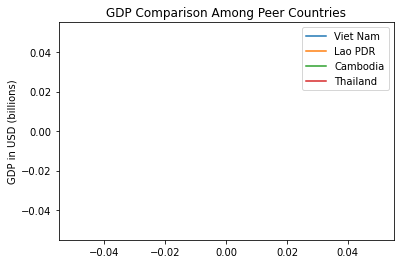

In [22]:
gdp_comparison_graph([ 'Viet Nam','Lao PDR','Cambodia', 'Thailand'])

In [23]:
def printgdps(cns):
  for cn in cns:
    print(round(aagrate([x[1] for x in gdp_13to18_dict[cn]]),2))

printgdps([ 'Viet Nam','Lao PDR','Cambodia', 'Thailand'])

ZeroDivisionError: ignored

ECI Peer Comparison Graph

In [24]:
def eci_comparison_graph(cnames):
  plt.ylabel('ECI')
  for country_name in cnames:
    if country_name == 'Plurinational State of Bolivia':
      label = 'Bolivia'
    elif country_name == 'Norway, Svalbard and Jan Mayen':
      label = 'Norway'
    elif country_name == 'Russian Federation':
      label = 'Russia'
    else:
      label = country_name
    plt.plot([x[0] for x in eci_13to18_dict[country_name]],[x[1] for x in eci_13to18_dict[country_name]], label=label)
    print(eci_13to18_dict[country_name])
  plt.legend()
  plt.title('ECI Comparison Among Peer Countries')
  plt.show()
  

[(2013, 0.46011389560832), (2014, 0.3728205766511358), (2015, 0.38553639193643446), (2016, 0.6743002496660582), (2017, 0.5409620943805893), (2018, 0.5744303490607177)]
[(2013, -0.5030583787950904), (2014, -0.5803206615940768), (2015, -0.4883127138887009), (2016, -0.654231821420567), (2018, -0.7787270176382651)]
[(2013, -0.4525713593757988), (2015, -0.16956179200676666), (2016, -0.17213022078150195)]
[(2013, 1.6532196600128257), (2014, 1.116005587197892), (2015, 1.4024829628082502), (2016, 1.3644128519750875), (2017, 1.4324979086753218), (2018, 1.2762381637640905)]


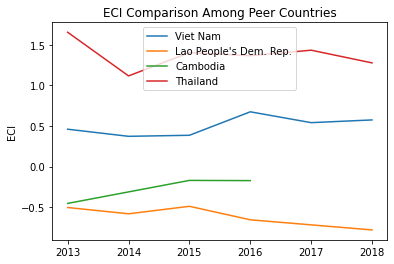

In [25]:
eci_comparison_graph([ 'Viet Nam','Lao People\'s Dem. Rep.','Cambodia', 'Thailand'])

In [ ]:
def eci_change(cns):
  for country_name in cns:
    print(round((eci_13to18_dict[country_name][len(eci_13to18_dict[country_name])-1][1]-eci_13to18_dict[country_name][0][1])/abs(eci_13to18_dict[country_name][0][1]) * 100,2))

eci_change(['Viet Nam','Lao People\'s Dem. Rep.','Cambodia', 'Thailand'])

24.85
-54.8
61.97
-22.8


GDP Growth and ECI Trend Graph

In [ ]:
def gdp_and_eci_graph(country_name):
  fig, ax1 = plt.subplots()
  ax1.set_ylabel('GDP in USD (billions)')
  ax1.plot([x[0] for x in gdp_13to18_dict[country_name]],[float(x[1])/(10**9) for x in gdp_13to18_dict[country_name]], color = 'red', label='GDP')
  ax2 = ax1.twinx()
  ax2.set_ylabel('ECI')
  if country_name=='Vietnam':
    country_name='Viet Nam'
  ax2.plot([x[0] for x in eci_13to18_dict[country_name]],[x[1] for x in eci_13to18_dict[country_name]], color = 'blue', label='ECI')
  ax1.legend()
  ax2.legend()
  plt.title('GDP and ECI Trend for ' + country_name)
  plt.show()

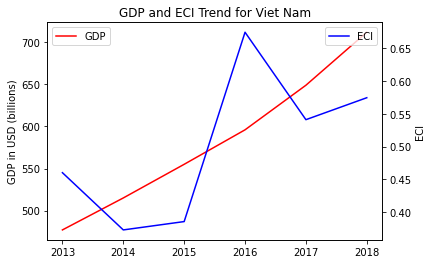

In [ ]:
gdp_and_eci_graph('Viet Nam')

# Proximity, Distance, and RID

Proximity

In [ ]:
def compute_proximity(mcp,product_sum):
  proximity = []
  for i in range(0,len(mcp[0])):
    product_row = []
    for j in range(0,len(mcp[0])):
      temp_sum = 0
      for k in range(0,len(mcp)):
        try:
          temp_sum += mcp[k][i] * mcp[k][j]
        except:
          pass
      p0 = product_sum[i]
      p1 = product_sum[j]
      if p0 < p1:
        large = p1
      else:
        large = p0
      product_row.append(temp_sum/large)
    proximity.append(product_row)
  return proximity

Distance

In [26]:
#compute distance
def compute_distance(mcp,proximity):
  distance = []
  for i in range(0,len(mcp)):
    product_row = []
    for j in range(0,len(mcp[0])):
      sum1 = 0
      for k in range(0,len(mcp[0])):
        if k != j:
          try:
            sum1 += mcp[i][k]*proximity[j][k]
          except:
            pass
      sum2 = 0
      for k in range(0,len(mcp[0])):
        if k != j:
          try:
            sum2 += proximity[j][k]
          except:
            pass
      product_row.append(1-sum1/sum2)
    distance.append(product_row)
  return distance

RID

In [ ]:
def compute_adi(df2,country_list,distance):
  raw_matrix = df2.to_numpy()
  matrix = [list(df2.columns)]
  for row in raw_matrix:
    if sum(row[1::]) > 0:
      matrix.append(list(row))

  country_list2,product_list2,mcp2,product_sum2,country_sum2 = compute_mcp(matrix)
  proximity2 = compute_proximity(mcp2,product_sum2)
  distance2 = compute_distance(mcp2,proximity2)

  adi = {}
  for i in range(len(country_list)):
    for j in range(len(country_list2)):
      if country_list[i] == country_list2[j]:
        adi[country_list[i]] = np.array(distance2[j]) - np.array(distance[i])
  return adi, country_list2,product_list2 

In [ ]:
proximity = compute_proximity(mcp,product_sum)
proximity_18 = compute_proximity(mcp_18,product_sum_18)

distance = compute_distance(mcp,proximity)
adi, country_list2,product_list2  = compute_adi(df2,country_list,distance)

In [ ]:
print(adi)

{'Bulgaria': array([-0.05132251,  0.09600379,  0.07423461,  0.05932781,  0.08967769,
       -0.00046295,  0.09081072,  0.11811772,  0.0444441 ,  0.05627533,
       -0.00423425, -0.06611971, -0.01466902,  0.07910997,  0.00904223,
        0.04290444, -0.055447  ,  0.05298151]), 'Myanmar': array([ 0.00147681,  0.01050518,  0.00648672,  0.02078825,  0.03176367,
        0.02279294, -0.08329288,  0.02770207, -0.0103845 ,  0.01166437,
        0.11103938,  0.05063554,  0.07057526,  0.05103436,  0.06393673,
       -0.00258577,  0.03346361, -0.03554381]), 'Burundi': array([-0.18769614, -0.21390923, -0.04915959, -0.11791564, -0.1508462 ,
       -0.17681541, -0.1634359 , -0.15781938, -0.18939672, -0.14591395,
       -0.18830008, -0.15527456, -0.10332406, -0.13642621, -0.12685813,
       -0.20729386, -0.09200456, -0.29162783]), 'Canada': array([-0.04706366, -0.04718487, -0.07119622, -0.05790699, -0.04563467,
       -0.07003395, -0.04526556, -0.05082901, -0.06699655, -0.03283929,
       -0.05847975,

In [ ]:
new_conts = ['Nigeria','Ukraine','Estonia','Canada','United Kingdom', 'Ireland', 'Sweden', 'Denmark', 'Israel', 'Lebanon', 'India', 'Pakistan', 'Chile', 'Kenya', 'Ghana', 'Qatar', 'Russian Federation', 'Norway, Svalbard and Jan Mayen','Viet Nam','Guatemala']

In [ ]:
df_ = pd.DataFrame()
df_['Category'] = product_list_18
df_['RID'] = adi[new_conts[0]]
df_.sort_values(by="RID")

,Category,RID
16,High-complexity Products,0.197362
1,"Vegetables, Fruits and Plants",0.221273
11,Machinery and Construction,0.230229
2,Food and Preparations,0.231866
6,Raw Manufacturing,0.241720
12,Transportation,0.252254
9,Textile,0.265901
17,Services and Utilities,0.285075
14,Daily Instruments,0.286427
5,Chemical Manufacturing,0.303036


# Sequential Strategy

Opportunity Gain

In [ ]:
def compute_opportunity_gain(mcp,proximity,pci):
  opportunity_gain = []
  for i in range(0,len(mcp)):
    country_row = []
    for j in range(0,len(mcp[0])):
      gain = 0
      for k in range(0,len(mcp[0])):
        temp = 0
        for l in range(0,len(mcp[0])):
          temp += proximity[l][k]
        gain += (proximity[j][k]/temp)*(1-mcp[i][k])*pci[k]
      gain = gain - (1-distance[i][j]) * pci[j]
      if mcp[i][j] == 1:
        country_row.append(0)
      else:
        country_row.append(gain)
      #country_row.append(gain)
    opportunity_gain.append(country_row)
    
  opportunity_gain = np.array(opportunity_gain)
  return opportunity_gain

Marginal Opportunity Gain

In [ ]:
def compute_marginal_opportunity_gain(mcp,opportunity_gain,country_sum,product_sum,matrix):
  marginal = []
  total_sum = np.sum(product_sum)
  for i in range(0,len(mcp)):
    country_row = []
    for j in range(0,len(mcp[0])):
      if mcp[i][j] == 1:
        country_row.append(0)
      else:
        export = matrix[i+1][j+1]
        country_export = country_sum[i]
        product_export = product_sum[j]
        export_increase = (product_export*country_export/total_sum)-export
        country_row.append(opportunity_gain[i][j]*export/export_increase)
    marginal.append(country_row)
    
  marginal = np.array(marginal)
  return marginal

In [ ]:
opportunity_gain = compute_opportunity_gain(mcp,proximity,pci)
opportunity_gain_18 = compute_opportunity_gain(mcp_18,proximity_18,pci_18)

marginal_opportunity_gain = compute_marginal_opportunity_gain(mcp,opportunity_gain,country_sum,product_sum,matrix)

#for i in range(len(country_list)):
#  print(country_list[i],opportunity_gain[i])

In [ ]:
# For computation of sequential strategies, refer to sequential strategy.py

In [ ]:
# For sensitivity analysis, refer to sensitivity.ipynb

In [ ]:
# For computation of SOI, soi.ipynb

# SDV & SIDS

In [27]:
def read_country(filename):
    f = open(filename,'r', encoding='utf-8')
    reader = csv.reader(f)
    raw_matrix = []
    for row in reader:
        temp = []
        for i in range(0,len(row)):
            try:
                temp.append(float(row[i]))
            except ValueError:
                temp.append(row[i])
        raw_matrix.append(temp)  
    f.close()
    return raw_matrix

def rank(score_dict):
    rank_list = []
    score_list = []
    for item in score_dict:
        score_list.append(score_dict[item])
    while score_list:
        maximum = max(score_list)
        for item in score_dict:
            if score_dict[item] == maximum:
                rank_list.append(item)
        score_list = [score for score in score_list if score!= maximum]
    return rank_list


def sdv_and_sids(country, year):
    #Read the raw matrix
    raw_matrix = read_country(f"{year}.csv")
    raw_matrix = [row for row in raw_matrix if np.all(row[1:]==np.zeros(len(row)-1)) == False]
    raw_matrix[19][3] = raw_matrix[19][3]
    #compute mcp
    product_list = raw_matrix[0][1::]
    country_list = []
    for i in range(1,len(raw_matrix)):
        country_list.append(raw_matrix[i][0])
    
    country_sum = []
    for i in range(1,len(raw_matrix)):
        country_sum.append(np.sum(raw_matrix[i][1::]))
    
    product_sum = []
    for i in range(1,len(raw_matrix[0])):
        product = 0
        for j in range(1,len(raw_matrix)):
            product += raw_matrix[j][i]
        product_sum.append(product)
    total_sum = np.sum(product_sum)
    
    print(product_list)
    print(country_list)

    mcp = []
    
    for i in range (1,len(raw_matrix)):
        country_row = []
        for j in range(1,len(raw_matrix[i])):
            percentage = raw_matrix[i][j]/country_sum[i-1]
            total_percentage = product_sum[j-1]/total_sum
            if percentage > total_percentage:
                country_row.append(1)
            else:
                country_row.append(0)
        mcp.append(country_row)
    
    #compute mpp
    country_sum2 = []
    for i in range(0,len(mcp)):
        country_sum2.append(np.sum(mcp[i]))
    
    product_sum2 = []
    for i in range(0,len(mcp[0])):
        product = 0
        for j in range(0,len(mcp)):
            product += mcp[j][i]
        product_sum2.append(product)
    
    mpp = []
    for i in range(0,len(mcp[0])):
        product_row = []
        for j in range(0,len(mcp[0])):
            temp_sum = 0
            for k in range(0,len(mcp)):
                try:
                    temp_sum += (mcp[k][i] * mcp[k][j]/(country_sum2[k]*product_sum2[i]))
                except:
                    pass
            product_row.append(temp_sum)
        mpp.append(product_row)
    
    #compute PCI
    mpp = np.array(mpp)
    
    e_vals, e_vecs = LA.eig(mpp)
    eigenvectors = e_vecs.tolist()
    eigen = []
    for eigenvector in eigenvectors:
        temp = []
        for col in eigenvector:
            temp.append(col.real)
        eigen.append(temp)
    
    vector = []
    for i in range(0,len(eigen)):
        vector.append(eigen[i][1])
    
    pci = []
    if vector[len(vector)-2] > 0:
        for item in vector:
            pci.append((item-np.mean(vector))/np.std(vector))
    else:
        for item in vector:
            pci.append((-item+np.mean(vector))/np.std(vector))
    
    #compute proximity
    proximity = []
    for i in range(0,len(mcp[0])):
        product_row = []
        for j in range(0,len(mcp[0])):
            temp_sum = 0
            for k in range(0,len(mcp)):
                try:
                    temp_sum += mcp[k][i] * mcp[k][j]
                except:
                    pass
            p0 = product_sum2[i]
            p1 = product_sum2[j]
            if p0 < p1:
                large = p1
            else:
                large = p0
            product_row.append(temp_sum/large)
        proximity.append(product_row)
    
    #compute actual distance
    distance = []
    for i in range(0,len(mcp)):
        product_row = []
        for j in range(0,len(mcp[0])):
            sum1 = 0
            for k in range(0,len(mcp[0])):
                try:
                    sum1 += (1-mcp[i][k])*proximity[j][k]
                except:
                    pass
            sum2 = 0
            for k in range(0,len(mcp[0])):
                try:
                    sum2 += proximity[j][k]
                except:
                    pass
            if mcp[i][j] == 1:
                product_row.append(0)
            else:
                product_row.append(sum1/sum2)
        distance.append(product_row)
    
    #compute opportunity gain
    opportunity_gain = []
    for i in range(0,len(mcp)):
        country_row = []
        for j in range(0,len(mcp[0])):
            gain = 0
            for k in range(0,len(mcp[0])):
                temp = 0
                for l in range(0,len(mcp[0])):
                    temp += proximity[l][k]
                gain += (proximity[j][k]/temp)*(1-mcp[i][k])*pci[k]
            gain = gain - (1-distance[i][j]) * pci[j]
            if mcp[i][j] == 1:
                country_row.append(0)
            else:
                country_row.append(gain)
        opportunity_gain.append(country_row)
        
    #compute marginal opportunity gain
    marginal = []
    for i in range(0,len(mcp)):
        country_row = []
        for j in range(0,len(mcp[0])):
            if mcp[i][j] == 1:
                country_row.append(0)
            else:
                export = raw_matrix[i+1][j+1]
                country_export = country_sum[i]
                product_export = product_sum[j]
                export_increase = (product_export*country_export/total_sum)-export
                country_row.append(opportunity_gain[i][j]*country_export/export_increase)
        marginal.append(country_row)
    
    
    #computing sequential strategy
    strategy = []
    
    for i in range(0,len(country_list)):
        if country in country_list[i]:
            country_index = i
    og = np.copy(opportunity_gain[country_index])
    sdv = dict(zip(product_list, og))
    sdv = sorted(sdv.items(), key=operator.itemgetter(1), reverse=True)
    sdv_colors = []
    for i in range(len(sdv)):
        if sdv[i][1]>0:
          sdv_colors.append(44)
        elif sdv[i][1]==0:
          sdv_colors.append(27)
        else:
          sdv_colors.append(1)
    print("Before Iteration: ")
    for i in range(0,len(marginal[country_index])):
        print(product_list[i], ": ", marginal[country_index][i])
    print(" ")
    
    temp = []
    temp.append("Before Iteration")
    posi = {}
    zero = []
    nega = {}
    colors = []
    color = [1]
    for i in range(0,len(marginal[country_index])):
        if marginal[country_index][i] > 0:
            posi[product_list[i]] = marginal[country_index][i]
        elif marginal[country_index][i] == 0:
            zero.append(product_list[i])
        else:
            nega[product_list[i]] = marginal[country_index][i]
    posi = rank(posi)
    nega = rank(nega)
    temp.extend(posi)
    color.extend([44 for i in range(len(posi))])
    temp.extend(zero)
    color.extend([27 for i in range(len(zero))])
    temp.extend(nega)
    color.extend([1 for i in range(len(nega))])
    strategy.append(temp)
    colors.append(color)
    
    ite_round = 0
    prev_industry = []
    
    while max(marginal[country_index]) > 0 and ite_round < 20:
        ite_round += 1
        
        value = max(marginal[country_index])
        for i in range(0,len(marginal[0])):
            if marginal[country_index][i] == value:
                industry_index = i
        industry = product_list[industry_index]
        prev_industry.append(industry_index)
        
        #calculate new export
        export = raw_matrix[country_index+1][industry_index+1]
        country_export = country_sum[country_index]
        product_export = product_sum[industry_index]
        required_export = product_export*country_export/total_sum
        export_increase = required_export-export
    
        print("increase ", industry, " in ", country, " by ", export_increase, " USD")
    
        raw_matrix[country_index+1][industry_index+1] = required_export*1.3
        
        #calculate everything again
        country_sum = []
        for i in range(1,len(raw_matrix)):
            country_sum.append(np.sum(raw_matrix[i][1::]))
    
        product_sum = []
        for i in range(1,len(raw_matrix[0])):
            product = 0
            for j in range(1,len(raw_matrix)):
                product += raw_matrix[j][i]
            product_sum.append(product)
        total_sum = np.sum(product_sum)
    
        mcp = []
     
        for i in range (1,len(raw_matrix)):
            country_row = []
            for j in range(1,len(raw_matrix[i])):
                percentage = raw_matrix[i][j]/country_sum[i-1]
                total_percentage = product_sum[j-1]/total_sum
                if percentage > total_percentage:
                    country_row.append(1)
                else:
                    country_row.append(0)
            mcp.append(country_row)
    
        #compute mpp
        country_sum2 = []
        for i in range(0,len(mcp)):
            country_sum2.append(np.sum(mcp[i]))
    
        product_sum2 = []
        for i in range(0,len(mcp[0])):
            product = 0
            for j in range(0,len(mcp)):
                product += mcp[j][i]
            product_sum2.append(product)
    
        mpp = []
        for i in range(0,len(mcp[0])):
            product_row = []
            for j in range(0,len(mcp[0])):
                temp_sum = 0
                for k in range(0,len(mcp)):
                    try:
                        temp_sum += (mcp[k][i] * mcp[k][j]/(country_sum2[k]*product_sum2[i]))
                    except:
                        pass
                product_row.append(temp_sum)
            mpp.append(product_row)
    
        #compute PCI
        mpp = np.array(mpp)
    
        e_vals, e_vecs = LA.eig(mpp)
        eigenvectors = e_vecs.tolist()
        eigen = []
        for eigenvector in eigenvectors:
            temp = []
            for col in eigenvector:
                temp.append(col.real)
            eigen.append(temp)
    
        vector = []
        for i in range(0,len(eigen)):
            vector.append(eigen[i][1])
    
        pci = []
        if vector[len(vector)-2] > 0:
            for item in vector:
                pci.append((item-np.mean(vector))/np.std(vector))
        else:
            for item in vector:
                pci.append((-item+np.mean(vector))/np.std(vector))
    
        #compute proximity
        proximity = []
        for i in range(0,len(mcp[0])):
            product_row = []
            for j in range(0,len(mcp[0])):
                temp_sum = 0
                for k in range(0,len(mcp)):
                    try:
                        temp_sum += mcp[k][i] * mcp[k][j]
                    except:
                        pass
                p0 = product_sum2[i]
                p1 = product_sum2[j]
                if p0 < p1:
                    large = p1
                else:
                    large = p0
                product_row.append(temp_sum/large)
            proximity.append(product_row)
    
        #compute actual distance
        distance = []
        for i in range(0,len(mcp)):
            product_row = []
            for j in range(0,len(mcp[0])):
                sum1 = 0
                for k in range(0,len(mcp[0])):
                    try:
                        sum1 += (1-mcp[i][k])*proximity[j][k]
                    except:
                        pass
                sum2 = 0
                for k in range(0,len(mcp[0])):
                    try:
                        sum2 += proximity[j][k]
                    except:
                        pass
                if mcp[i][j] == 1:
                    product_row.append(0)
                else:
                    product_row.append(sum1/sum2)
            distance.append(product_row)
    
        #compute opportunity gain
        opportunity_gain = []
        for i in range(0,len(mcp)):
            country_row = []
            for j in range(0,len(mcp[0])):
                gain = 0
                for k in range(0,len(mcp[0])):
                    temp = 0
                    for l in range(0,len(mcp[0])):
                        temp += proximity[l][k]
                    gain += (proximity[j][k]/temp)*(1-mcp[i][k])*pci[k]
                gain = gain - (1-distance[i][j]) * pci[j]
                if mcp[i][j] == 1:
                    country_row.append(0)
                else:
                    country_row.append(gain)
            opportunity_gain.append(country_row)
        
        #compute marginal opportunity gain
        marginal = []
        for i in range(0,len(mcp)):
            country_row = []
            for j in range(0,len(mcp[0])):
                if mcp[i][j] == 1:
                    country_row.append(0)
                else:
                    export = raw_matrix[i+1][j+1]
                    country_export = country_sum[i]
                    product_export = product_sum[j]
                    export_increase = (product_export*country_export/total_sum)-export
                    country_row.append(opportunity_gain[i][j]*country_export/export_increase)
            marginal.append(country_row)
        
        print("Iteration ", ite_round, ": ")
        for i in range(0,len(marginal[country_index])):
            print(product_list[i], ": ", marginal[country_index][i])
        print(" ")
        
        temp = []
        string = "Iteration " + str(ite_round)
        temp.append(string)
        posi = {}
        zero = []
        nega = {}
        color = [1]
        for i in range(0,len(marginal[country_index])):
            if marginal[country_index][i] > 0:
                posi[product_list[i]] = marginal[country_index][i]
            elif marginal[country_index][i] == 0:
                zero.append(product_list[i])
            else:
                nega[product_list[i]] = marginal[country_index][i]
        posi = rank(posi)
        nega = rank(nega)
        temp.extend(posi)
        color.extend([44 for i in range(len(posi))])
        temp.extend(zero)
        color.extend([27 for i in range(len(zero))])
        temp.extend(nega)
        color.extend([1 for i in range(len(nega))])
        strategy.append(temp)
        colors.append(color)
    
    strategy = np.array(strategy)
    strategy = np.transpose(strategy)
    colors = np.array(colors)
    colors = np.transpose(colors)
    #print(f'color shape is {colors.shape}')

    book = Workbook()
    sheet1 = book.add_sheet('Sheet 1')
    for i in range(0,len(strategy)):
        for j in range(len(strategy[0])):
          st = xlwt.easyxf('pattern: pattern solid;')
          st.pattern.pattern_fore_colour = colors[i][j]
          sheet1.write(i,j,strategy[i][j], st)
    book.save(f'sequential strategy of {country}.xls')
    
    book = Workbook()
    sheet1 = book.add_sheet('Sheet 1')
    for i in range(0,len(sdv)):
          st = xlwt.easyxf('pattern: pattern solid;')
          st.pattern.pattern_fore_colour = sdv_colors[i]
          sheet1.write(i, 0, sdv[i][0], st)
    book.save(f'sequential vector of {country}.xls')
    print(f'{country} completed')
    
def main():
    countries = ['Viet Nam','Lao People\'s Dem. Rep.','Cambodia', 'Thailand']
               
    for country in countries:
        sdv_and_sids(country, root_path+'2013-2018 cleaned/2018clean')

In [ ]:

if __name__ == "__main__":
    main()   #Change the countries and year above to have different results

/usr/local/lib/python3.7/dist-packages/ipykernel_launcher.py:33: FutureWarning: elementwise comparison failed; returning scalar instead, but in the future will perform elementwise comparison


['Animals and By-products', 'Vegetables, Fruits and Plants', 'Food and Preparations', 'Energy Drilling and Mining', 'Chemicals', 'Chemical Manufacturing', 'Raw Manufacturing', 'Wood Products', 'Clothing and Accessories', 'Textile', 'Metals', 'Machinery and Construction', 'Transportation', 'Weapons', 'Daily Instruments', 'Precious Stones', 'High-complexity Products', 'Services and Utilities ']
['Bulgaria', 'Myanmar', 'Burundi', 'Belarus', 'Canada', 'Cabo Verde', 'Chile', 'China', 'Colombia', 'Costa Rica', 'Croatia', 'Cyprus', 'Andorra', 'Czechia', 'Benin', 'Denmark', 'Ecuador', 'El Salvador', 'Estonia', 'Angola', 'Fiji', 'Finland', 'France, Monaco', 'Georgia', 'Gambia', 'State of Palestine', 'Germany', 'Antigua and Barbuda', 'Ghana', 'Greece', 'Greenland', 'Azerbaijan', 'Argentina', 'Guyana', 'China, Hong Kong Special Administrative Region', 'Hungary', 'Iceland', 'Australia', 'Indonesia', 'Ireland', 'Israel', 'Italy', "C̫te d'Ivoire", 'Japan', 'Kazakhstan', 'Afghanistan', 'Austria', 'Jo

UnboundLocalError: ignored

Greedy Algorithm

In [ ]:
def greedy(country, year, percentage, num_part):
    df = pd.read_csv(root_path+'2013-2018 cleaned/2018clean.csv')
    raw_matrix = df.to_numpy()
    matrix = [list(df.columns)]

    for row in raw_matrix:
      if np.min(row[1::]) > 0:
        matrix.append(list(row))
    
    print(len(raw_matrix))
    product_list = matrix[0][1::]
    print(product_list)
    country_list = []
    for i in range(1,len(matrix)):
        country_list.append(matrix[i][0])
        if country in matrix[i][0]:
           country_index = i
           #print(country_index)
           total_export = np.sum(matrix[i][1::])
    
    budget = (percentage/100) * total_export
    print(f'Original total export is {total_export}, budget is {budget}')
    mcp = compute_mcp(matrix)[2]
    mcc = compute_mcc(mcp)
    last_eci = compute_eci(mcc)[country_index-1]
    print(f'ECI this year is {last_eci}')
    each_amount = budget/num_part
    original_vector = np.copy(matrix[country_index][1::])

    total = 0
    while total < budget:
        eci = []
        print(f'Progress: {round(total/budget, 2)}')
        for i in tqdm(range(1, len(matrix[0]))):
            matrix[country_index][i] += each_amount
            mcp = compute_mcp(matrix)[2]
            mcc = compute_mcc(mcp)
            eci.append(compute_eci(mcc)[country_index - 1])
            matrix[country_index][i] -= each_amount
        if  eci.count(max(eci)) != 1:
            #print('path 2')
            multiple = 2
            total_temp = total
            temp_each = multiple*each_amount
            while max(eci)<=last_eci and total_temp < budget:
                temp_each = multiple*each_amount
                print(f'Multiple = {multiple}, Raise each amount to {temp_each}')
                eci = []
                for i in tqdm(range(1, len(matrix[0]))):
                    matrix[country_index][i] += temp_each
                    mcp = compute_mcp(matrix)[2]
                    mcc = compute_mcc(mcp)
                    eci.append(compute_eci(mcc)[country_index - 1])
                    matrix[country_index][i] -= temp_each
                multiple += 1
                total_temp = total + temp_each
            if max(eci)<=last_eci and total_temp == budget:
               print('ECI does not change any more, add to the most adjacent ')
               export_increase = []
               mcp, product_sum, country_sum = compute_mcp(matrix)[2:]
               total_sum = np.sum(product_sum)
               for j in range(0,len(mcp[0])):
                  if mcp[country_index-1][j] == 1:
                      export_increase.append(0)
                  else:
                      export = raw_matrix[country_index][j+1]
                      country_export = country_sum[country_index-1]
                      product_export = product_sum[j]
                      export_increase.append((product_export*country_export/total_sum)-export)
               country_dist = np.array(export_increase)
               min_distance = np.where(country_dist > 0, country_dist, np.inf).argmin()
               matrix[country_index][min_distance + 1] += temp_each
            else:
               matrix[country_index][np.argmax(eci) + 1] += temp_each
               print(eci)
               print(f'After increasing, largest argument is {np.argmax(eci) + 1}, product is {product_list[np.argmax(eci)]}')
               print(f'last_eci is {last_eci}, this_eci is {max(eci)}')
            total = total_temp
            last_eci = max(eci)
        else:
            #print('path 3')
            largest_component = np.argmax(eci) + 1
            print(eci)
            print(f'largest argument is {np.argmax(eci) + 1}, product is {product_list[np.argmax(eci)]}')
            print(f'last_eci is {last_eci}, this_eci is {max(eci)}')
            last_eci = max(eci)
            matrix[country_index][np.argmax(eci) + 1] += each_amount
            total += each_amount
    optimal_vector = np.array(matrix[country_index][1::]) - original_vector
    max_eci = last_eci
    return dict(zip(product_list,optimal_vector)), max_eci

In [ ]:
greedy('Viet Nam', 2018, 10, 12)

138
['Animals and By-products', 'Vegetables, Fruits and Plants', 'Food and Preparations', 'Energy Drilling and Mining', 'Chemicals', 'Chemical Manufacturing', 'Raw Manufacturing', 'Wood Products', 'Clothing and Accessories', 'Textile', 'Metals', 'Machinery and Construction', 'Transportation', 'Weapons', 'Daily Instruments', 'Precious Stones', 'High-complexity Products', 'Services and Utilities ']
Original total export is 266180237615.0, budget is 26618023761.5
ECI this year is 0.574430349060719
Progress: 0.0


100%|██████████| 18/18 [00:23<00:00,  1.30s/it]


Multiple = 2, Raise each amount to 4436337293.583333


100%|██████████| 18/18 [00:23<00:00,  1.30s/it]


Multiple = 3, Raise each amount to 6654505940.375


...

100%|██████████| 18/18 [00:24<00:00,  1.37s/it]


Multiple = 3, Raise each amount to 6654505940.375


100%|██████████| 18/18 [00:24<00:00,  1.39s/it]

[0.6243761166894544, 0.57538183603722, 0.48147618357258715, 0.6243761166894544, 0.6210174692323847, 0.6243761166894544, 0.6243761166894544, 0.6243761166894544, 0.6243761166894544, 0.6229798168188946, 0.5251319334878244, 0.6243761166894544, 0.6243761166894544, 0.5514353132568347, 0.6243761166894544, 0.6243761166894544, 0.6243761166894544, 0.5671604817230091]
After increasing, largest argument is 1, product is Animals and By-products
last_eci is 0.6243761166894544, this_eci is 0.6243761166894544


({'Animals and By-products': 6654505940.374996,
  'Chemical Manufacturing': 11090843233.958332,
  'Chemicals': 0.0,
  'Clothing and Accessories': 0.0,
  'Daily Instruments': 7.62939453125e-06,
  'Energy Drilling and Mining': 0.0,
  'Food and Preparations': 0.0,
  'High-complexity Products': 0.0,
  'Machinery and Construction': -3.814697265625e-06,
  'Metals': -3.814697265625e-06,
  'Precious Stones': 0.0,
  'Raw Manufacturing': -3.814697265625e-06,
  'Services and Utilities ': 11090843233.958332,
  'Textile': 0.0,
  'Transportation': -3.814697265625e-06,
  'Vegetables, Fruits and Plants': -3.814697265625e-06,
  'Weapons': 0.0,
  'Wood Products': 0.0},
 0.6243761166894544)

# SOI

In [ ]:
def read_it(filename):
    f = open(filename,'r', encoding='cp1252')
    reader = csv.reader(f)
    raw_matrix = []
    for row in reader:
        temp = []
        for i in range(0,len(row)):
            try:
                temp.append(float(row[i]))
            except ValueError:
                #print(row[i])
                temp.append(row[i])
        raw_matrix.append(temp)  
    f.close()
    return raw_matrix

In [ ]:
zzz+=1
def compute_soi_adi(adi, country_list, product_list,country_list2, product_list2, opportunity_gain):
    soi = {}
    if len(product_list) == len(product_list2):
        print("categorization verified")

    common = []
    for i in range(0,len(country_list)):
        if country_list[i] in country_list2:
            for j in range(0,len(country_list2)):
                if country_list[i] == country_list2[j]:
                    dependent = adi[country_list[i]]
                    independent = []
                    for item in opportunity_gain[i]:
                        independent.append(item)
                    dfs=  pd.DataFrame({'I': independent, 'D': dependent})
                    model = smf.ols(formula='D ~ I', data=dfs).fit()
                    r_2 = model.rsquared_adj
                    plt.scatter(independent, dependent)
                    plt.show()
                    print(model.cov_HC0)
                    print(country_list[i], "!!!")
                    print(country_list2[j], "???")
                    common.append(country_list[i])
                    soi[country_list[i]] =r_2
                    
    matrix = open(root_path+"Rohan Testing/structual optimality index adi ("+str(zzz)+ ").csv",'w',newline='')
    writer = csv.writer(matrix)
    col_name = ["Country","SOI"]
    writer.writerow(col_name)
    for i in range(0,len(soi)):
       temp = [common[i],soi[common[i]]]
       writer.writerow(temp)
    matrix.close()
    return soi

In [ ]:
def compute_soi_oppgain(country_list, product_list,country_list2, product_list2, opportunity_gain, opportunity_gain2):
    soi = {}
    if len(product_list) == len(product_list2):
        print("categorization verified")

    common = []
    for i in range(0,len(country_list)):
        if country_list[i] in country_list2:
            for j in range(0,len(country_list2)):
                if country_list[i] == country_list2[j]:
                    independent=[]
                    dependent=[]
                    for item in opportunity_gain2[j]:
                        #dependent.append([item])
                        dependent.append(item)
                    for item in opportunity_gain[i]:
                        #independent.append([item])
                        independent.append(item)
                    # reg = LinearRegression()
                    # reg.fit(independent, dependent)
                    # r_2 = reg.score(independent, dependent)
                    dfs=  pd.DataFrame({'I': independent, 'D': dependent})
                    model = smf.ols(formula='D ~ I', data=dfs).fit()
                    r_2 = model.rsquared_adj
                    common.append(country_list[i])
                    soi[country_list[i]] =r_2

    matrix = open(root_path+"Rohan Testing/structual optimality index oppgain.csv",'w',newline='')
    writer = csv.writer(matrix)
    col_name = ["Country","SOI"]
    writer.writerow(col_name)
    for i in soi.keys():
        temp = [i,soi[i]]
        writer.writerow(temp)
    matrix.close()
    return soi

In [ ]:
def compute_soi_exp(country_list, product_list,country_list2, product_list2, opportunity_gain, exp_change):
    soi = {}
    if len(product_list) == len(product_list2):
        print("categorization verified")
    for i in range(0,len(country_list)):
        if country_list[i] in country_list2:
            for j in range(0,len(country_list2)):
                if country_list[i] == country_list2[j]:
                    dependent = []
                    independent = []
                    for item in opportunity_gain[i]:
                        #independent.append([item])
                        independent.append(item)
                    #print(opportunity_gain2[i])
                    for item in exp_change.loc[country_list[i],:]:
                        #dependent.append([item])
                        dependent.append(item)
                    #reg = LinearRegression()
                    #reg.fit(independent, dependent)
                    #r_2 = reg.score(independent, dependent)
                    dfs=  pd.DataFrame({'I':independent, 'D': dependent})
                    model = smf.ols(formula='D ~ I', data=dfs).fit()
                    r_2 = model.rsquared_adj
                    soi[country_list[i]] = r_2
                    
    matrix = open(root_path+"Rohan Testing/structual optimality index oppgain.csv",'w',newline='')
    writer = csv.writer(matrix)
    col_name = ["Country","SOI"]
    writer.writerow(col_name)
    for i in soi.keys():
        temp = [i,soi[i]]
        writer.writerow(temp)
    matrix.close()
    return soi

In [ ]:
def compute_regress(soi, gdp_raw, country_list, country_list2):
    #comprehensive regression
    common=np.intersect1d(country_list, country_list2)
    independent = []
    dependent = []
    name = []
    common2= []
    growth={}
    for i in common:
        if i in gdp_raw.index.values and gdp_raw['2013'][i] != 0:
            pct_change=(float(gdp_raw['2018'][i])-float(gdp_raw['2013'][i]))/float(gdp_raw['2013'][i])
            dependent.append(pct_change)
            independent.append(soi[i])
            growth[i]=pct_change
            common2.append(i)
    # plt.scatter(independent,dependent)
    # plt.title('SOI v GDP Growth')
    # plt.xlabel('SOI')
    # plt.ylabel('% Change in GDP')
    # plt.show()
    
    # print(np.setdiff1d(common,common2))
    # print()
    # print(common)
    # print()
    # print(common2)
  
    dfs=  pd.DataFrame({'Country': common2,'GDP':dependent, 'SOI': independent})
    #dfs.set_index('Country', inplace=True)
    model = smf.ols(formula='GDP ~ SOI', data=dfs).fit()


    fig = px.scatter(dfs, x="SOI", y="GDP",  text='Country', trendline="ols") 
    fig.update_layout(
    title="Regression of GDP over SOI",
    yaxis_title="% Growth in GDP 2013-2018",
    xaxis_title="SOI",
    height=600,
    width=900,
    title_x=.5,
    font=dict(
        family="Times New Roman",
        size=15
        ) )
    #fig.update_traces(textposition='top center')
    fig.show()
    fig2 = plt.figure(figsize=(12,8))
    fig2 = sm.graphics.plot_regress_exog(model,'SOI', fig=fig2)
    fig3, ax = plt.subplots(figsize=(12,8))
    fig3 = sm.graphics.influence_plot(model, ax=ax, criterion='Cooks')
    return model, growth

In [ ]:
def compute_opportunity_gain(mcp,proximity,pci):
  opportunity_gain = []
  for i in range(0,len(mcp)):
    country_row = []
    for j in range(0,len(mcp[0])):
      gain = 0
      for k in range(0,len(mcp[0])):
        temp = 0
        for l in range(0,len(mcp[0])):
          temp += proximity[l][k]
        gain += (proximity[j][k]/temp)*(1-mcp[i][k])*pci[k]
      gain = gain - (1-distance[i][j]) * pci[j]
      country_row.append(gain)
    opportunity_gain.append(country_row)
    
  opportunity_gain = np.array(opportunity_gain)
  return opportunity_gain

opportunity_gain = compute_opportunity_gain(mcp,proximity,pci)
opportunity_gain_18 = compute_opportunity_gain(mcp_18,proximity_18,pci_18)

marginal_opportunity_gain = compute_marginal_opportunity_gain(mcp,opportunity_gain,country_sum,product_sum,matrix)


In [ ]:

def soi_plotter(country, adi, country_list, product_list,country_list2, product_list2, opportunity_gain):
    if len(product_list) == len(product_list2):
            print("categorization verified")
    for i in range(0,len(country_list)):
        if country_list[i] in country_list2 and country_list[i]==country:
            for j in range(0,len(country_list2)):
                if country_list[i] == country_list2[j]:
                    dependent = adi[country_list[i]]
                    independent = []
                    for item in opportunity_gain[i]:
                        independent.append(item)
                    # print(independent)
                    # print(dependent)
                    # print(product_list)
                    # Create figure with secondary y-axis
                    fig = make_subplots(specs=[[{"secondary_y": True}]])

                    # Add traces
                    fig.add_trace(
                        go.Scatter(x=product_list, y=independent, name="Opportunity Gain"),
                        secondary_y=False,
                    )

                    fig.add_trace(
                        go.Scatter(x=product_list, y=dependent, name="RID"),
                        secondary_y=True,
                    )

                    # Add figure title
                    fig.update_layout(
                        title_text="SOI of "+country
                    )
                    fig.update_layout(
                        height=600,
                        width=1500,
                        title_x=.5,
                        font=dict(
                            family="Times New Roman",
                            size=15
                            ) )
                    # Set x-axis title
                    fig.update_xaxes(title_text="Product Category")

                    # Set y-axes titles
                    fig.update_yaxes(title_text="RID", secondary_y=False)
                    fig.update_yaxes(title_text="Opportunity Gain", secondary_y=True)

                    correlation_matrix = np.corrcoef(dependent, independent)
                    correlation_xy = correlation_matrix[0,1]
                    r_squared = correlation_xy**2
                    print("ASDFASDFASDFSADFASDFASDFASDF R^2: ", r_squared, "ASDFASDFASDFASDF)\n\n\n")
                    fig.show()
                        
                      

SOI w/ ADI

categorization verified


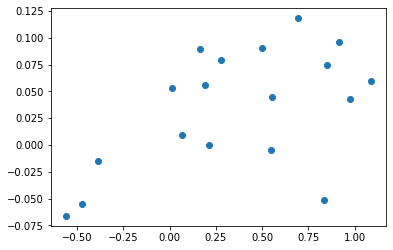

[[ 1.27809974e-04 -8.90750636e-05]
 [-8.90750636e-05  4.11790076e-04]]
Bulgaria !!!
Bulgaria ???


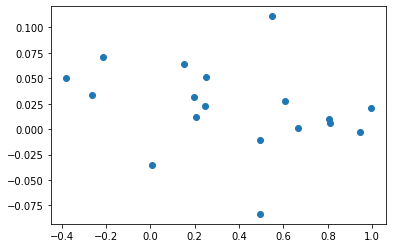

[[ 1.06559462e-04 -6.27300314e-05]
 [-6.27300314e-05  2.06135216e-04]]
Myanmar !!!
Myanmar ???


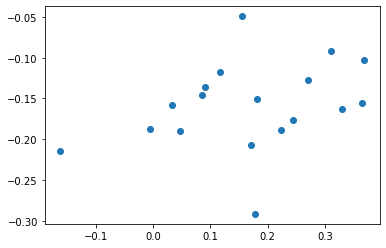

[[ 0.00015226 -0.00019183]
 [-0.00019183  0.0017379 ]]
Burundi !!!
Burundi ???


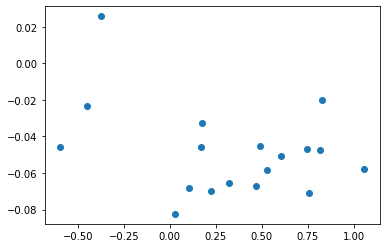

[[ 7.69983004e-05 -1.06144096e-04]
 [-1.06144096e-04  2.00793957e-04]]
Canada !!!
Canada ???


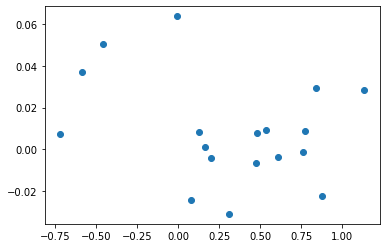

[[ 4.78450127e-05 -4.61718479e-05]
 [-4.61718479e-05  1.18473262e-04]]
Chile !!!
Chile ???


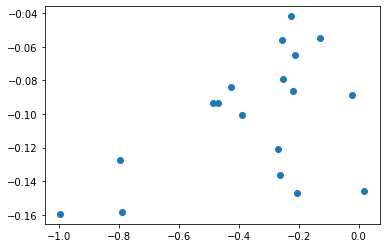

[[0.00023165 0.00037747]
 [0.00037747 0.00073852]]
China !!!
China ???


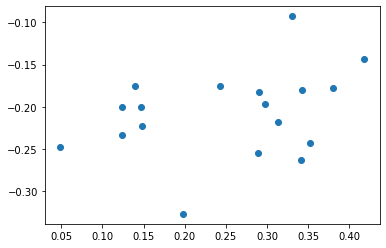

[[ 0.00044237 -0.00149892]
 [-0.00149892  0.00689628]]
Colombia !!!
Colombia ???


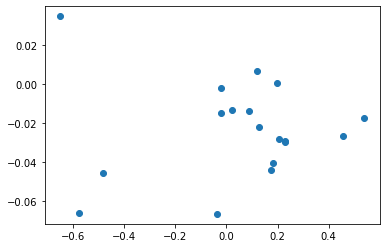

[[ 4.44101324e-05 -1.51324576e-04]
 [-1.51324576e-04  8.28007620e-04]]
Costa Rica !!!
Costa Rica ???


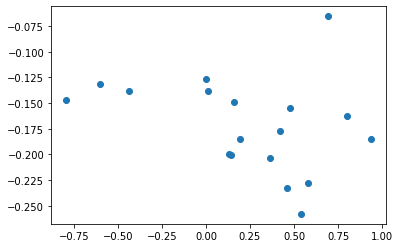

[[5.38478904e-05 6.48896985e-05]
 [6.48896985e-05 3.49655972e-04]]
Croatia !!!
Croatia ???


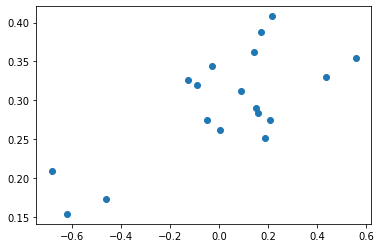

[[1.15993545e-04 2.88119197e-05]
 [2.88119197e-05 8.04901560e-04]]
Cyprus !!!
Cyprus ???


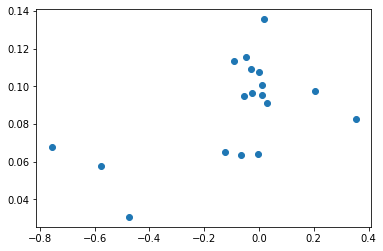

[[2.81195545e-05 3.24421284e-05]
 [3.24421284e-05 3.55345806e-04]]
Andorra !!!
Andorra ???


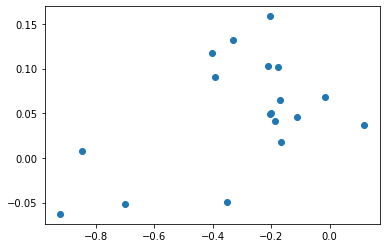

[[0.00028027 0.00043249]
 [0.00043249 0.00149937]]
Czechia !!!
Czechia ???


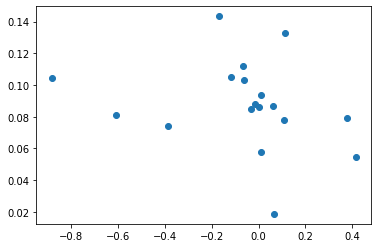

[[4.34882835e-05 3.44313040e-05]
 [3.44313040e-05 1.74278033e-04]]
Denmark !!!
Denmark ???


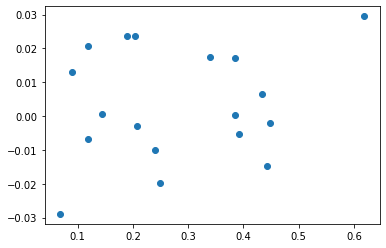

[[ 8.30831588e-05 -2.26650786e-04]
 [-2.26650786e-04  7.35334638e-04]]
Ecuador !!!
Ecuador ???


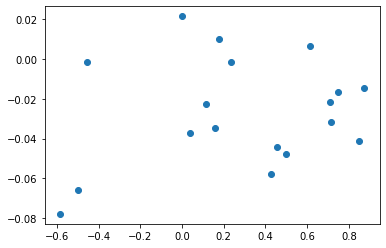

[[ 8.20604635e-05 -1.12363703e-04]
 [-1.12363703e-04  2.33995013e-04]]
El Salvador !!!
El Salvador ???


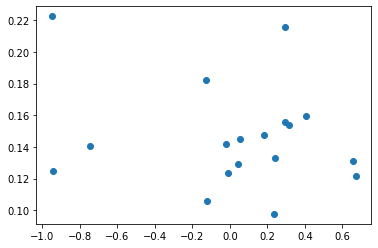

[[ 5.75353774e-05 -5.89842622e-05]
 [-5.89842622e-05  3.89735686e-04]]
Estonia !!!
Estonia ???


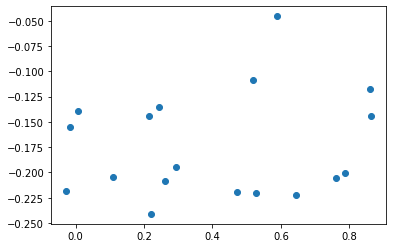

[[ 0.00022419 -0.00032645]
 [-0.00032645  0.00108389]]
Fiji !!!
Fiji ???


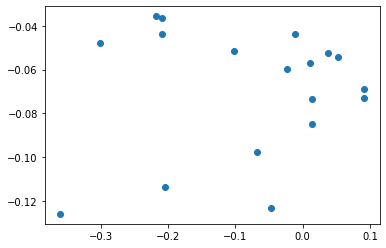

[[2.85730682e-05 3.93158476e-05]
 [3.93158476e-05 3.29826376e-03]]
Finland !!!
Finland ???


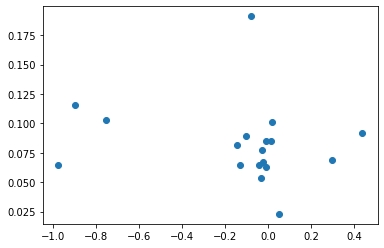

[[6.72466180e-05 4.19471848e-05]
 [4.19471848e-05 2.33290004e-04]]
France, Monaco !!!
France, Monaco ???


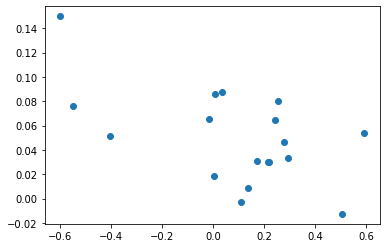

[[ 6.34836186e-05 -9.41289642e-05]
 [-9.41289642e-05  7.73717415e-04]]
Georgia !!!
Georgia ???


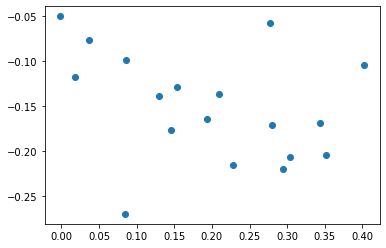

[[ 0.00077612 -0.00292311]
 [-0.00292311  0.0140506 ]]
Gambia !!!
Gambia ???


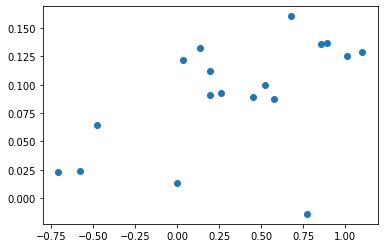

[[ 7.80232605e-05 -1.34728710e-05]
 [-1.34728710e-05  2.16622748e-04]]
State of Palestine !!!
State of Palestine ???


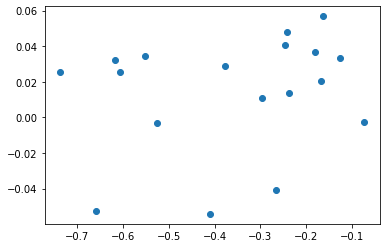

[[0.00016985 0.00038293]
 [0.00038293 0.00123677]]
Germany !!!
Germany ???


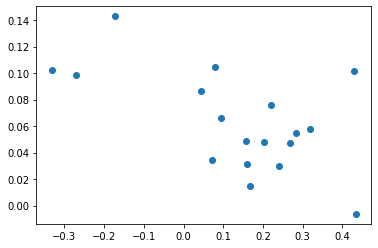

[[ 5.04172852e-05 -1.00278195e-04]
 [-1.00278195e-04  1.39588271e-03]]
Antigua and Barbuda !!!
Antigua and Barbuda ???


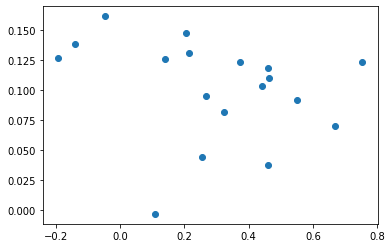

[[ 0.0002317  -0.00038825]
 [-0.00038825  0.00097876]]
Ghana !!!
Ghana ???


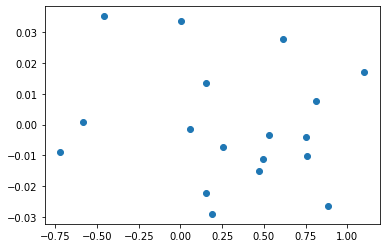

[[ 2.90736112e-05 -2.77412341e-05]
 [-2.77412341e-05  7.57871754e-05]]
Greece !!!
Greece ???


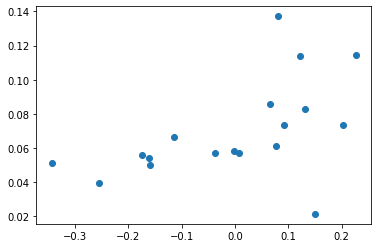

[[3.34771509e-05 1.49759688e-04]
 [1.49759688e-04 9.76993181e-04]]
Greenland !!!
Greenland ???


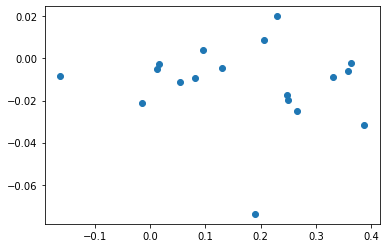

[[ 1.63700324e-05 -9.16510316e-06]
 [-9.16510316e-06  2.43529744e-04]]
Azerbaijan !!!
Azerbaijan ???


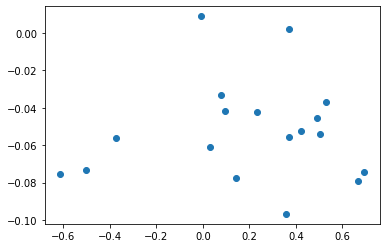

[[ 4.43907405e-05 -3.26805716e-05]
 [-3.26805716e-05  1.82431759e-04]]
Guatemala !!!
Guatemala ???


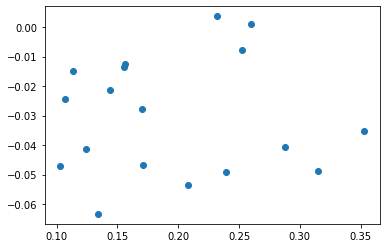

[[ 0.00011158 -0.00049321]
 [-0.00049321  0.00267053]]
Guyana !!!
Guyana ???


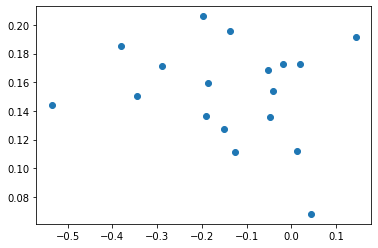

[[0.00015669 0.0005044 ]
 [0.0005044  0.00231896]]
China, Hong Kong Special Administrative Region !!!
China, Hong Kong Special Administrative Region ???


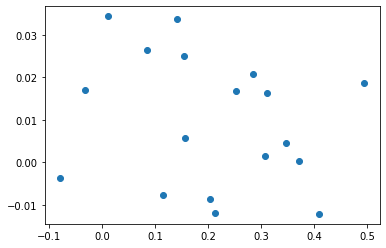

[[ 4.28900142e-05 -1.30692326e-04]
 [-1.30692326e-04  5.39747431e-04]]
Iceland !!!
Iceland ???


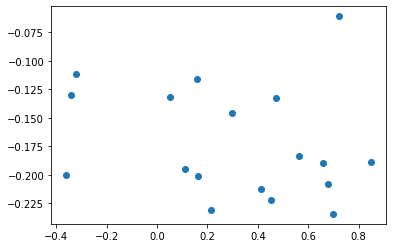

[[ 0.00014747 -0.00018666]
 [-0.00018666  0.00092305]]
Indonesia !!!
Indonesia ???


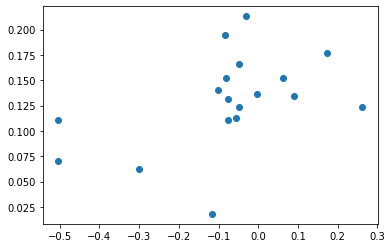

[[9.87709906e-05 9.25843544e-05]
 [9.25843544e-05 1.24628031e-03]]
Ireland !!!
Ireland ???


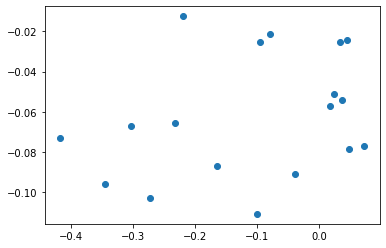

[[5.67474222e-05 1.13860476e-04]
 [1.13860476e-04 1.03399906e-03]]
Israel !!!
Israel ???


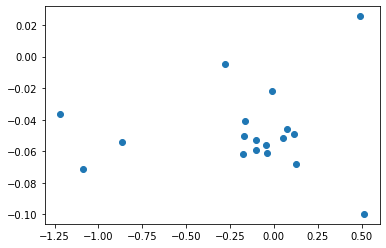

[[6.88279359e-05 1.20393143e-04]
 [1.20393143e-04 3.07179838e-04]]
Italy !!!
Italy ???


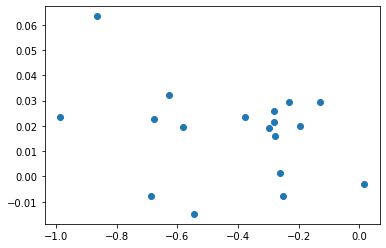

[[4.22702382e-05 9.40051234e-05]
 [9.40051234e-05 3.01214363e-04]]
Japan !!!
Japan ???


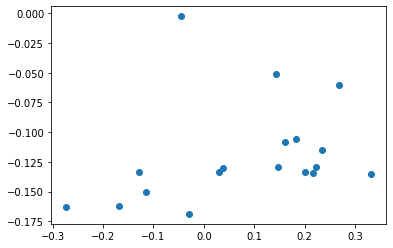

[[ 0.00012395 -0.00032246]
 [-0.00032246  0.00221309]]
Kazakhstan !!!
Kazakhstan ???


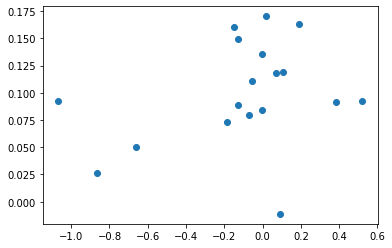

[[1.25168109e-04 9.71991685e-05]
 [9.71991685e-05 4.90575917e-04]]
Austria !!!
Austria ???


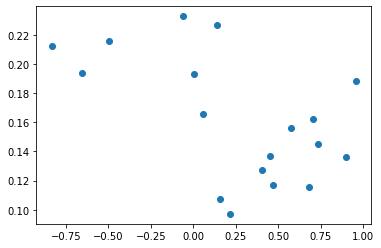

[[ 7.03950493e-05 -1.82231202e-05]
 [-1.82231202e-05  1.30895756e-04]]
Jordan !!!
Jordan ???


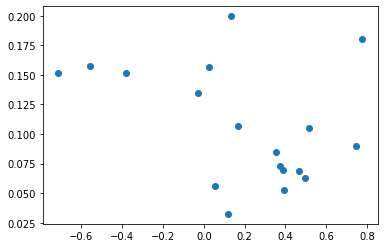

[[9.04585369e-05 5.59962506e-06]
 [5.59962506e-06 5.15596656e-04]]
Kenya !!!
Kenya ???


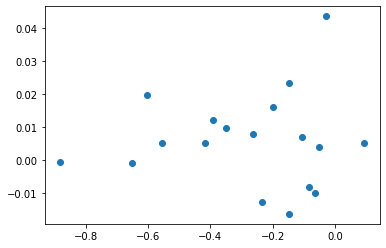

[[3.40159575e-05 5.91055085e-05]
 [5.91055085e-05 1.25414316e-04]]
Republic of Korea !!!
Republic of Korea ???


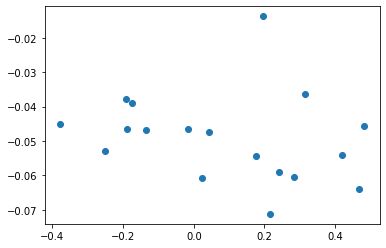

[[6.36986886e-06 8.67060934e-06]
 [8.67060934e-06 6.05005173e-05]]
Kuwait !!!
Kuwait ???


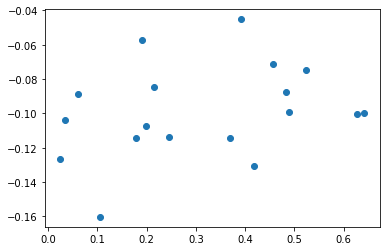

[[ 0.00012705 -0.00025008]
 [-0.00025008  0.00066851]]
Kyrgyzstan !!!
Kyrgyzstan ???


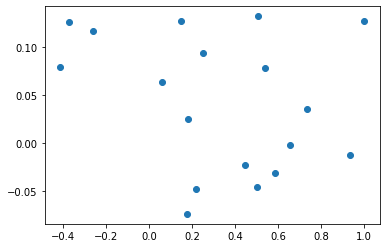

[[ 0.00028434 -0.00027081]
 [-0.00027081  0.00124263]]
Lao People's Dem. Rep. !!!
Lao People's Dem. Rep. ???


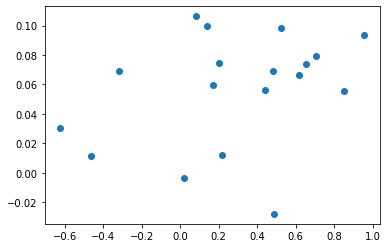

[[ 8.46674022e-05 -5.23245842e-05]
 [-5.23245842e-05  1.59354205e-04]]
Lebanon !!!
Lebanon ???


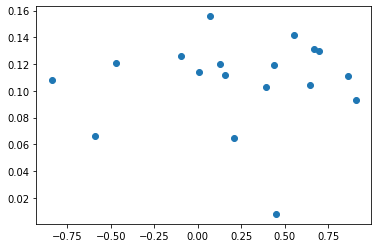

[[ 5.87249877e-05 -1.38650438e-05]
 [-1.38650438e-05  1.25957127e-04]]
Latvia !!!
Latvia ???


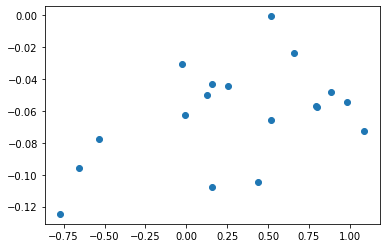

[[ 5.12592509e-05 -3.17920916e-05]
 [-3.17920916e-05  9.99398611e-05]]
Lithuania !!!
Lithuania ???


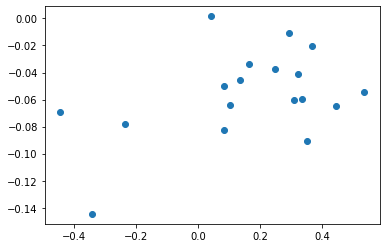

[[ 9.12179202e-05 -2.17580465e-04]
 [-2.17580465e-04  9.42760274e-04]]
Luxembourg !!!
Luxembourg ???


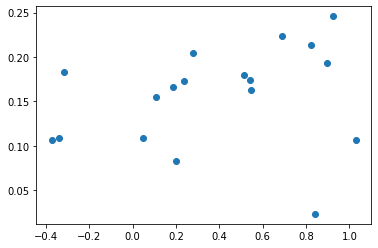

[[ 0.00012556 -0.00014095]
 [-0.00014095  0.00096348]]
Madagascar !!!
Madagascar ???


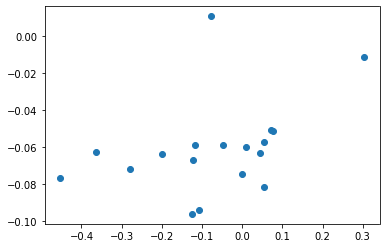

[[3.54872493e-05 6.15735390e-05]
 [6.15735390e-05 5.25669204e-04]]
Malaysia !!!
Malaysia ???


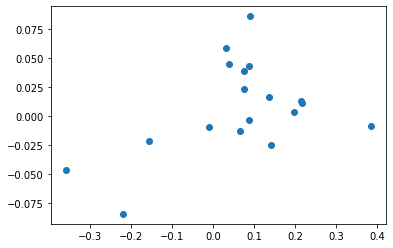

[[ 7.77647247e-05 -1.60180303e-04]
 [-1.60180303e-04  2.48807795e-03]]
Malta !!!
Malta ???


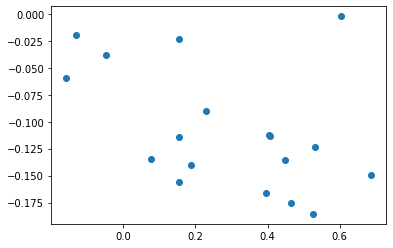

[[ 0.00021838 -0.00052381]
 [-0.00052381  0.00266181]]
Mauritius !!!
Mauritius ???


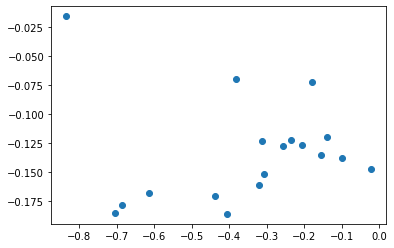

[[0.00037444 0.00129   ]
 [0.00129    0.00515717]]
Mexico !!!
Mexico ???


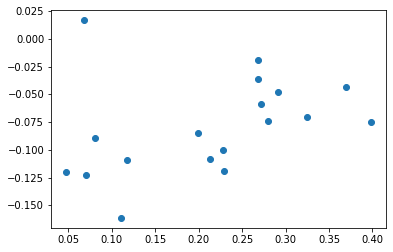

[[ 0.0008035  -0.00275695]
 [-0.00275695  0.01007546]]
Mongolia !!!
Mongolia ???


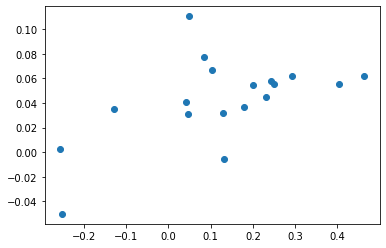

[[ 9.80420090e-05 -2.96521774e-04]
 [-2.96521774e-04  1.30576667e-03]]
Republic of Moldova !!!
Republic of Moldova ???


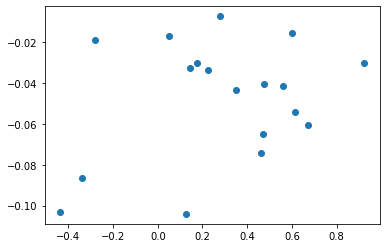

[[ 0.00010403 -0.00016309]
 [-0.00016309  0.00036065]]
Montenegro !!!
Montenegro ???


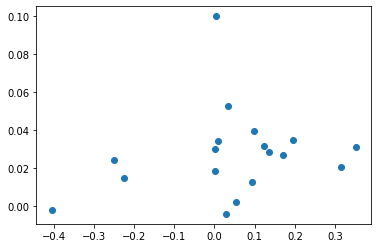

[[ 2.97851993e-05 -3.83827585e-05]
 [-3.83827585e-05  2.71594263e-04]]
Morocco !!!
Morocco ???


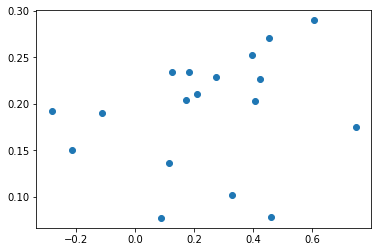

[[ 0.00018425 -0.00022695]
 [-0.00022695  0.00199162]]
Mozambique !!!
Mozambique ???


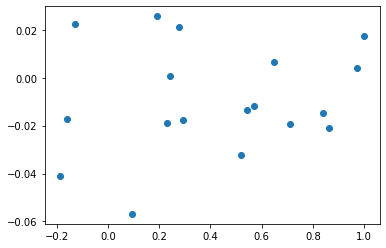

[[ 9.30773927e-05 -1.22042068e-04]
 [-1.22042068e-04  2.00916290e-04]]
Armenia !!!
Armenia ???


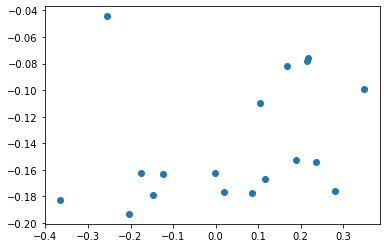

[[ 0.00011889 -0.00029175]
 [-0.00029175  0.00334572]]
Oman !!!
Oman ???


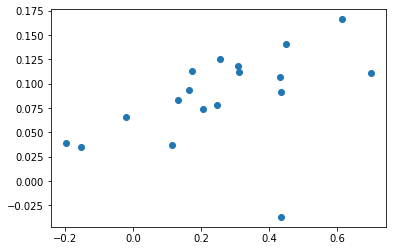

[[ 4.01400320e-05 -5.21487584e-05]
 [-5.21487584e-05  1.17866771e-03]]
Namibia !!!
Namibia ???


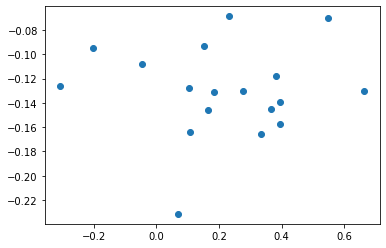

[[ 0.00013616 -0.00024105]
 [-0.00024105  0.00094044]]
Barbados !!!
Barbados ???


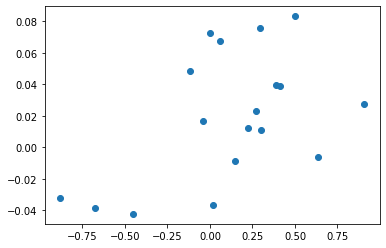

[[ 6.32479513e-05 -4.02629340e-06]
 [-4.02629340e-06  2.22398185e-04]]
Netherlands !!!
Netherlands ???


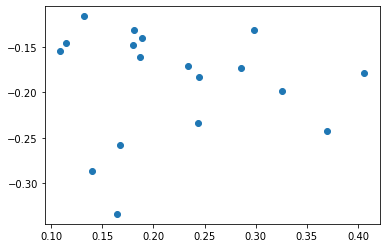

[[ 0.00159407 -0.00527927]
 [-0.00527927  0.01896432]]
Aruba !!!
Aruba ???


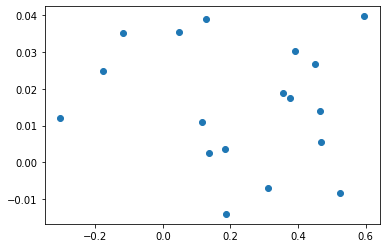

[[ 1.98992922e-05 -3.45562993e-05]
 [-3.45562993e-05  1.99131363e-04]]
New Zealand !!!
New Zealand ???


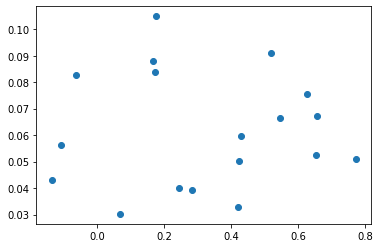

[[ 6.72321781e-05 -1.00518124e-04]
 [-1.00518124e-04  2.18043313e-04]]
Nicaragua !!!
Nicaragua ???


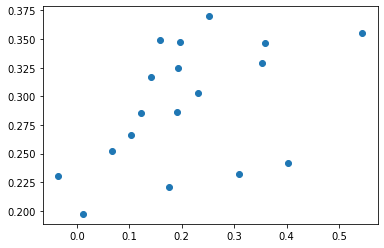

[[ 0.00024636 -0.00076858]
 [-0.00076858  0.00439626]]
Nigeria !!!
Nigeria ???


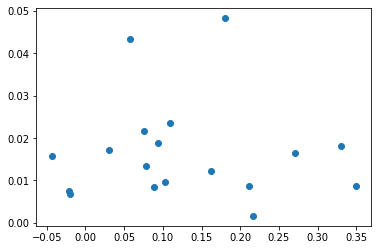

[[ 1.18727216e-05 -3.64768508e-05]
 [-3.64768508e-05  3.07744054e-04]]
Norway, Svalbard and Jan Mayen !!!
Norway, Svalbard and Jan Mayen ???


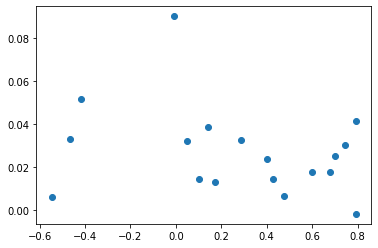

[[ 4.53396029e-05 -6.26474031e-05]
 [-6.26474031e-05  1.36812506e-04]]
Pakistan !!!
Pakistan ???


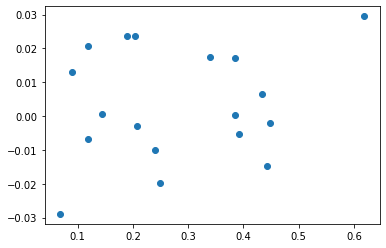

[[ 8.30831588e-05 -2.26650786e-04]
 [-2.26650786e-04  7.35334638e-04]]
Paraguay !!!
Paraguay ???


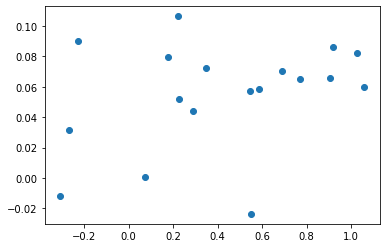

[[ 0.0001681  -0.00019306]
 [-0.00019306  0.00030093]]
Peru !!!
Peru ???


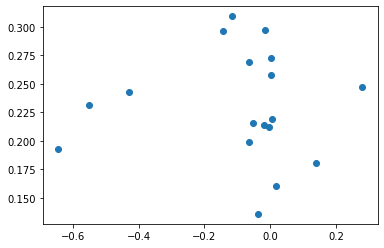

[[0.00014525 0.00017515]
 [0.00017515 0.00099322]]
Philippines !!!
Philippines ???


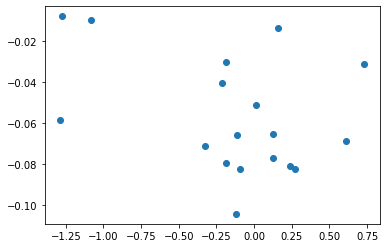

[[4.00295067e-05 2.25374730e-05]
 [2.25374730e-05 1.40521957e-04]]
Poland !!!
Poland ???


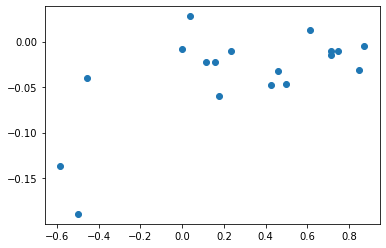

[[ 0.00024865 -0.00039341]
 [-0.00039341  0.00074408]]
Portugal !!!
Portugal ???


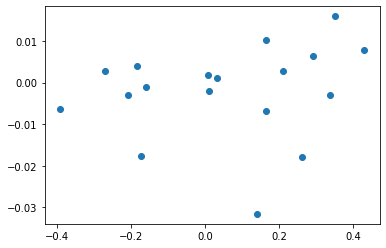

[[5.52745163e-06 5.84136295e-06]
 [5.84136295e-06 7.21274267e-05]]
Qatar !!!
Qatar ???


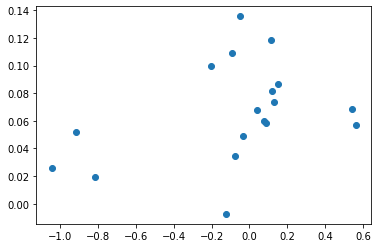

[[6.10697922e-05 1.59040151e-05]
 [1.59040151e-05 1.06100094e-04]]
Romania !!!
Romania ???


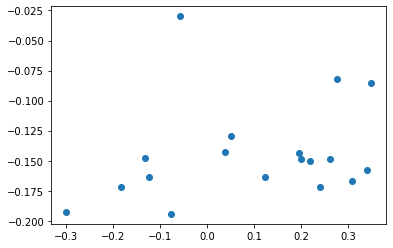

[[ 0.00012162 -0.00029671]
 [-0.00029671  0.00197058]]
Russian Federation !!!
Russian Federation ???


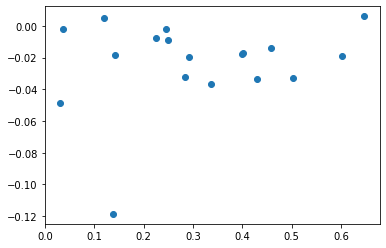

[[ 0.00028269 -0.0006086 ]
 [-0.0006086   0.00138779]]
Plurinational State of Bolivia !!!
Plurinational State of Bolivia ???


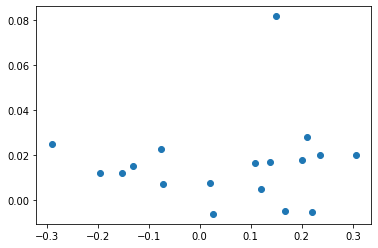

[[1.44031684e-05 3.64811929e-05]
 [3.64811929e-05 3.19021329e-04]]
Saudi Arabia !!!
Saudi Arabia ???


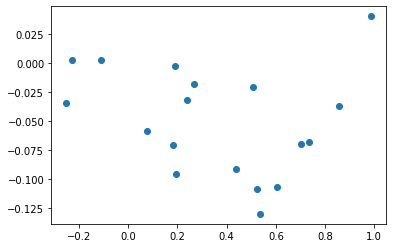

[[ 0.00014344 -0.00027585]
 [-0.00027585  0.00127238]]
Senegal !!!
Senegal ???


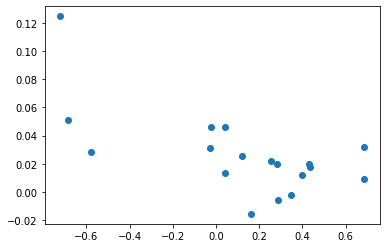

[[ 4.61690602e-05 -1.01041241e-04]
 [-1.01041241e-04  3.95783809e-04]]
Serbia !!!
Serbia ???


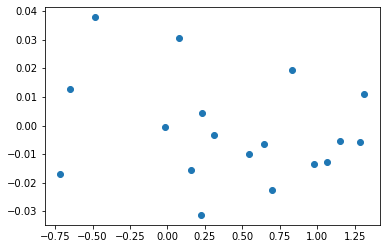

[[ 3.55200122e-05 -3.29095686e-05]
 [-3.29095686e-05  4.82499688e-05]]
India !!!
India ???


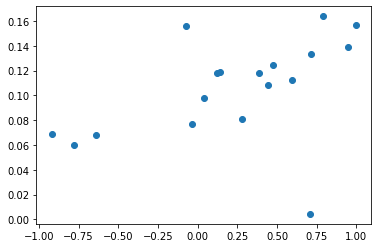

[[4.43106402e-05 3.15589802e-05]
 [3.15589802e-05 1.56747762e-04]]
Bosnia Herzegovina !!!
Bosnia Herzegovina ???


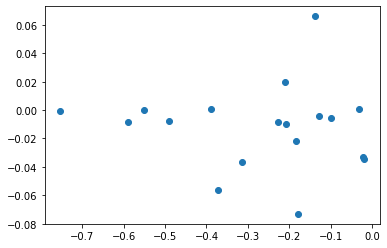

[[0.00012864 0.00021074]
 [0.00021074 0.00044485]]
Singapore !!!
Singapore ???


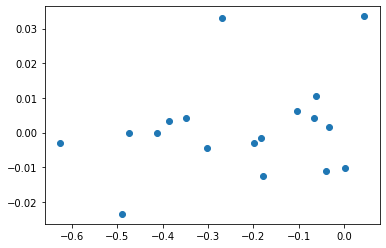

[[3.03204223e-05 7.59328682e-05]
 [7.59328682e-05 2.67633304e-04]]
Slovakia !!!
Slovakia ???


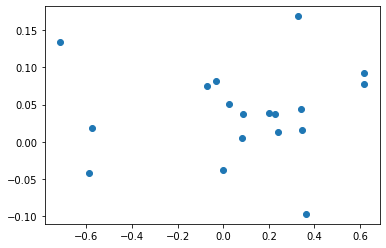

[[ 0.00022614 -0.00020829]
 [-0.00020829  0.00208891]]
Viet Nam !!!
Viet Nam ???


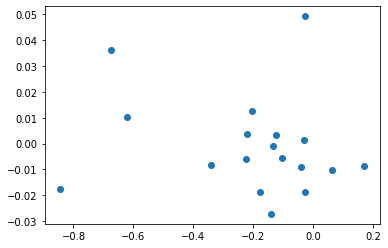

[[3.07713243e-05 7.13104602e-05]
 [7.13104602e-05 4.06065469e-04]]
Slovenia !!!
Slovenia ???


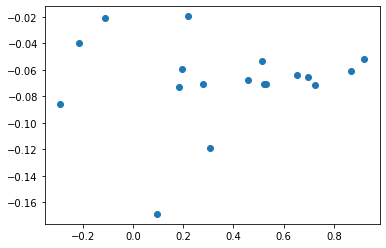

[[ 0.00020522 -0.00027456]
 [-0.00027456  0.00040443]]
South Africa !!!
South Africa ???


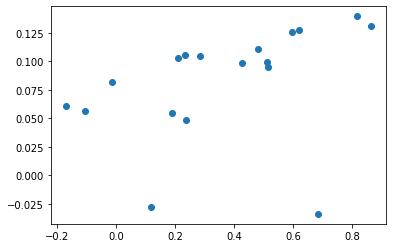

[[ 0.00016811 -0.00031237]
 [-0.00031237  0.0012742 ]]
Zimbabwe !!!
Zimbabwe ???


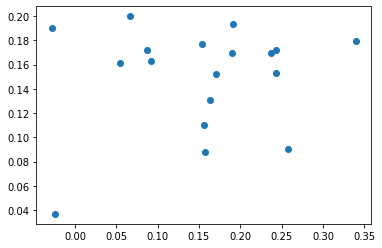

[[ 0.00075553 -0.00362852]
 [-0.00362852  0.01924135]]
Botswana !!!
Botswana ???


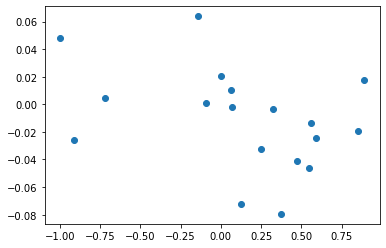

[[ 6.82272096e-05 -3.54495620e-05]
 [-3.54495620e-05  1.96213817e-04]]
Spain !!!
Spain ???


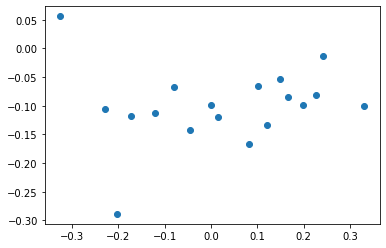

[[ 0.00033233 -0.00190383]
 [-0.00190383  0.01651286]]
Suriname !!!
Suriname ???


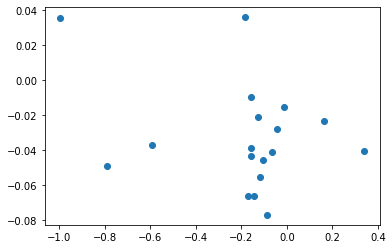

[[4.60791265e-05 6.56913987e-05]
 [6.56913987e-05 6.55250328e-04]]
Sweden !!!
Sweden ???


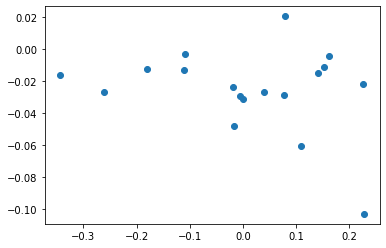

[[3.02865839e-05 1.62611463e-04]
 [1.62611463e-04 1.58501465e-03]]
Switzerland, Liechtenstein !!!
Switzerland, Liechtenstein ???


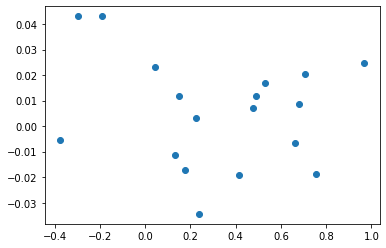

[[ 5.83919174e-05 -9.00295952e-05]
 [-9.00295952e-05  2.20745825e-04]]
Brazil !!!
Brazil ???


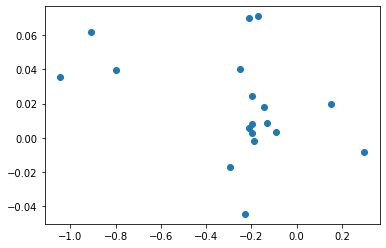

[[5.45312725e-05 3.86708063e-05]
 [3.86708063e-05 9.84946232e-05]]
Thailand !!!
Thailand ???


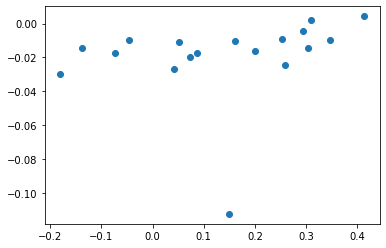

[[ 3.16051275e-05 -1.52014167e-05]
 [-1.52014167e-05  2.09311398e-04]]
United Arab Emirates !!!
United Arab Emirates ???


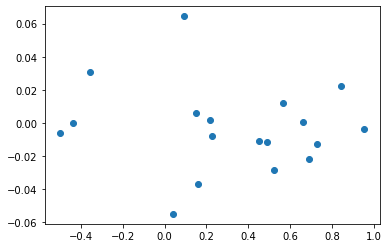

[[ 6.60125226e-05 -6.76610615e-05]
 [-6.76610615e-05  1.22202559e-04]]
Turkey !!!
Turkey ???


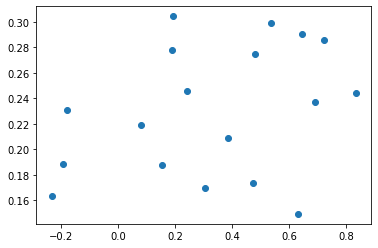

[[ 0.00015099 -0.00017078]
 [-0.00017078  0.00075701]]
Albania !!!
Albania ???


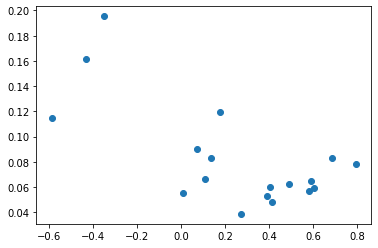

[[ 0.00011251 -0.00019394]
 [-0.00019394  0.00049681]]
Uganda !!!
Uganda ???


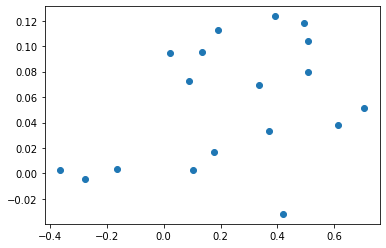

[[ 1.08979278e-04 -9.11670395e-05]
 [-9.11670395e-05  7.13851046e-04]]
Ukraine !!!
Ukraine ???


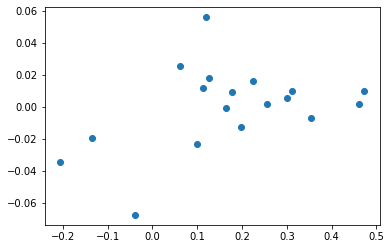

[[ 7.96558146e-05 -2.04398422e-04]
 [-2.04398422e-04  6.89795001e-04]]
The Former Yugoslav Republic of Macedonia !!!
The Former Yugoslav Republic of Macedonia ???


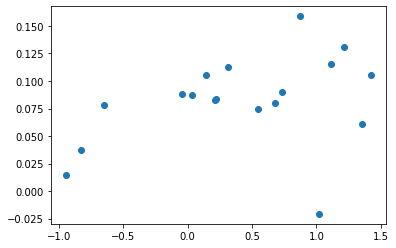

[[ 5.76311242e-05 -6.76096246e-06]
 [-6.76096246e-06  1.58650667e-04]]
Egypt !!!
Egypt ???


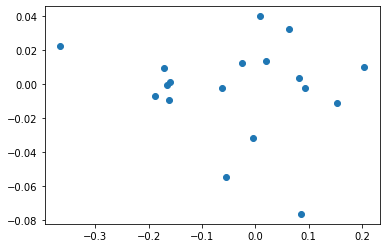

[[5.19030019e-05 1.69542100e-04]
 [1.69542100e-04 1.20965449e-03]]
United Kingdom !!!
United Kingdom ???


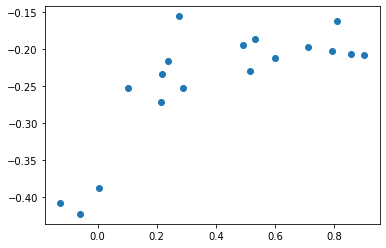

[[ 0.00065078 -0.00097406]
 [-0.00097406  0.00174386]]
United Republic of Tanzania !!!
United Republic of Tanzania ???


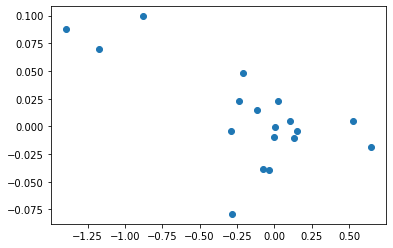

[[5.83952883e-05 5.28943091e-06]
 [5.28943091e-06 1.15015750e-04]]
USA, Puerto Rico and US Virgin Islands !!!
USA, Puerto Rico and US Virgin Islands ???


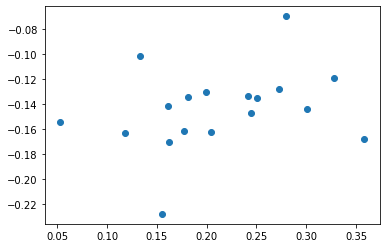

[[ 0.0004629  -0.00192069]
 [-0.00192069  0.00896792]]
Burkina Faso !!!
Burkina Faso ???


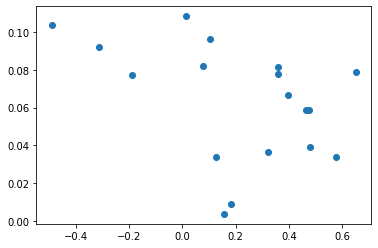

[[ 5.01565894e-05 -3.65336341e-05]
 [-3.65336341e-05  1.76602595e-04]]
Uruguay !!!
Uruguay ???


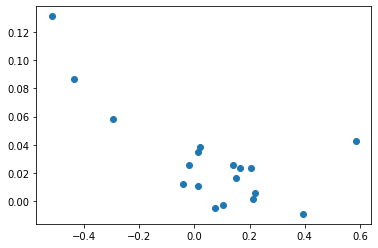

[[ 3.12079270e-05 -3.95675732e-05]
 [-3.95675732e-05  1.32783984e-03]]
Samoa !!!
Samoa ???


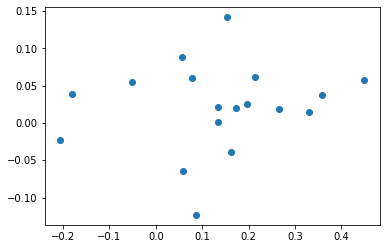

[[ 0.00028274 -0.00051365]
 [-0.00051365  0.00190106]]
Zambia !!!
Zambia ???


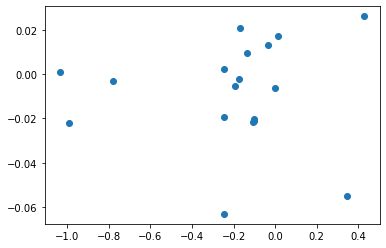

[[5.75371987e-05 8.91915120e-05]
 [8.91915120e-05 2.20635865e-04]]
NAFTA !!!
NAFTA ???


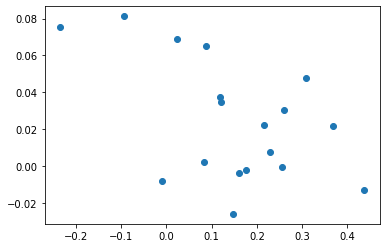

[[ 8.12353380e-05 -2.20995092e-04]
 [-2.20995092e-04  1.12595407e-03]]
Argentina !!!
Argentina ???


FileNotFoundError: ignored

In [ ]:
soi_adi= compute_soi_adi(adi, country_list, product_list,country_list2, product_list2, opportunity_gain)
soi_adi_list = sorted(soi_adi.items(), key=operator.itemgetter(1))
gdp_raw=pd.read_csv(root_path+'GDP4.csv', index_col=0).fillna(0)
print(gdp_raw)
reg, growth= compute_regress(soi_adi, gdp_raw, country_list, country_list2)
# print(len(country_list))
# print(len(country_list2))
# print(len(soi_adi_list))
reg.summary()

In [ ]:
c= 'United Kingdom'
sorted_x = sorted(soi_adi.items(), key=lambda kv: kv[1], reverse=True)
for i in range(len(sorted_x)):
  print(i, "  ", sorted_x[i])
soi_plotter(c, adi, country_list, product_list, country_list2, product_list2, opportunity_gain)
print('SOI', soi_adi[c],'Growth', growth[c])
for i in growth.keys():
 # if i=='Viet Nam':
  #  i='Vietnam'
  print(i, "\t", growth[i])

0    ('United Republic of Tanzania', 0.543790292776139)
1    ('Cyprus', 0.5028537951220258)
2    ('Samoa', 0.4857067061440501)
3    ('Uganda', 0.430948778713942)
4    ('USA, Puerto Rico and US Virgin Islands', 0.3991854754266677)
5    ('Serbia', 0.38377061027489723)
6    ('Portugal', 0.34862185304604665)
7    ('Antigua and Barbuda', 0.3041825713425368)
8    ('Georgia', 0.2835485073646562)
9    ('Republic of Moldova', 0.25643000707665253)
10    ('Bulgaria', 0.24795253806311313)
11    ('Jordan', 0.24273692120608548)
12    ('Argentina', 0.23422552327704838)
13    ('State of Palestine', 0.23377311697153236)
14    ('Andorra', 0.23346080109941614)
15    ('Netherlands', 0.21779740298212702)
16    ('Greenland', 0.20633030610225322)
17    ('Czechia', 0.1965648390031507)
18    ('Nigeria', 0.1748153405151276)
19    ('Namibia', 0.16861454678314713)
20    ('Bosnia Herzegovina', 0.1675261704950144)
21    ('China', 0.1614993087907156)
22    ('Ireland', 0.15575170044758335)
23    ('Lithuania', 0.15423

NameError: ignored

SOI w/ Opportunity Gain

categorization verified
[('Andorra', 0.9146585409206541), ('Antigua and Barbuda', 0.5867938373294832), ('Argentina', 0.7486639941183386), ('Armenia', 0.7514719138470592), ('Aruba', 0.3520279525194001), ('Austria', 0.9013436014321712), ('Azerbaijan', 0.2992983619831324), ('Barbados', 0.7447156423841568), ('Bosnia Herzegovina', 0.7773441545113247), ('Botswana', 0.537493277426391), ('Brazil', -0.024239878548463878), ('Bulgaria', 0.9435853142049964), ('Burkina Faso', -0.051329196561545), ('Burundi', 0.6571123840038602), ('Canada', 0.24744388156615293), ('Chile', 0.8771278379379186), ('China', 0.7352045312813527), ('China, Hong Kong Special Administrative Region', 0.44842065421189226), ('Colombia', -0.06162180408596951), ('Costa Rica', 0.9372383721603565), ('Croatia', 0.7055130476055648), ('Cyprus', 0.029905494336734506), ('Czechia', 0.8171702876916453), ('Denmark', 0.76687615449943), ('Ecuador', 0.5667279576504243), ('Egypt', 0.915005751146281), ('El Salvador', 0.8630636001708661), ('Eston

AttributeError: ignored

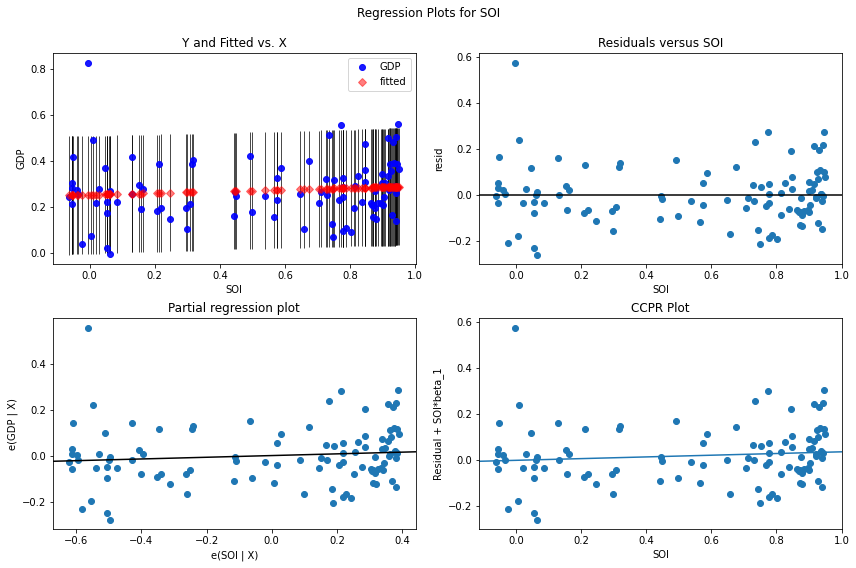

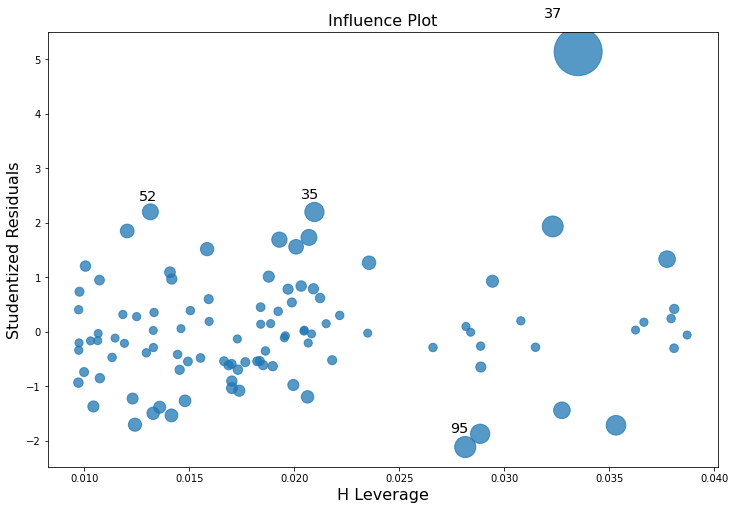

In [ ]:
soi_oppg= compute_soi_oppgain(country_list, product_list,country_list_18, product_list_18, opportunity_gain, opportunity_gain_18)
print(sorted(soi_oppg.items(), key=operator.itemgetter(0)))
#print(np.intersect1d(country_list,country_list_18))
reg_opp= compute_regress(soi_oppg, gdp_raw, country_list, country_list_18)
reg_opp.summary()

categorization verified
[('Andorra', -0.05820516938059672), ('Antigua and Barbuda', 0.1393539793985954), ('Argentina', -0.06222831235646664), ('Armenia', 0.014109720426524697), ('Aruba', -0.016298780277182123), ('Austria', -0.04965458655925592), ('Azerbaijan', -0.0157742696732055), ('Barbados', 0.12611364009224424), ('Bosnia Herzegovina', -0.02720558934318107), ('Botswana', -0.030963638105219626), ('Brazil', -0.028309684037119975), ('Bulgaria', 0.39392091568102217), ('Burkina Faso', -0.025662719360140196), ('Burundi', -0.06089491327998875), ('Canada', 0.0055444583969762595), ('Chile', -0.06241399152365634), ('China', -0.04720000624077203), ('China, Hong Kong Special Administrative Region', 0.054402525711019445), ('Colombia', 0.0294011249078725), ('Costa Rica', 0.07064723702695064), ('Croatia', -0.06249915230149816), ('Cyprus', -0.06249657536495046), ('Czechia', -0.042582315708255214), ('Denmark', 0.08600653977314343), ('Ecuador', -0.030958472560595585), ('Egypt', -0.034988853966852806)

AttributeError: ignored

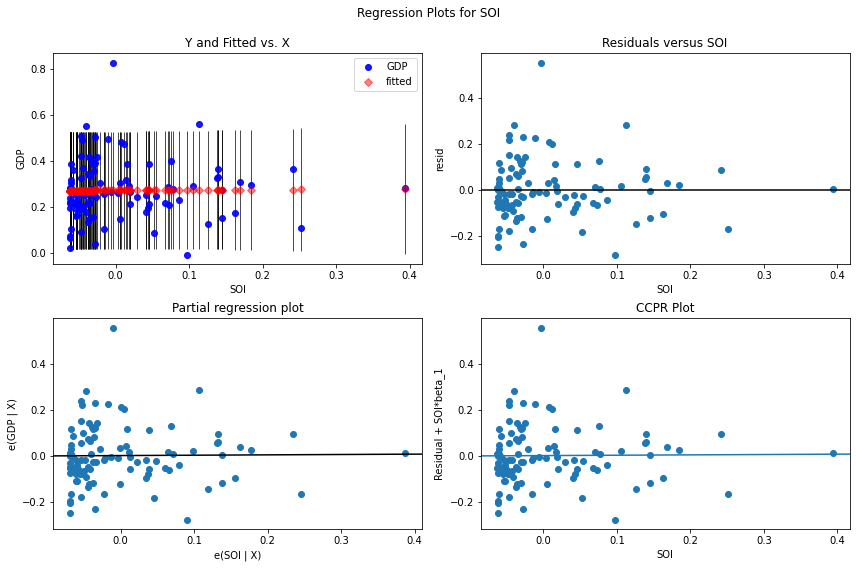

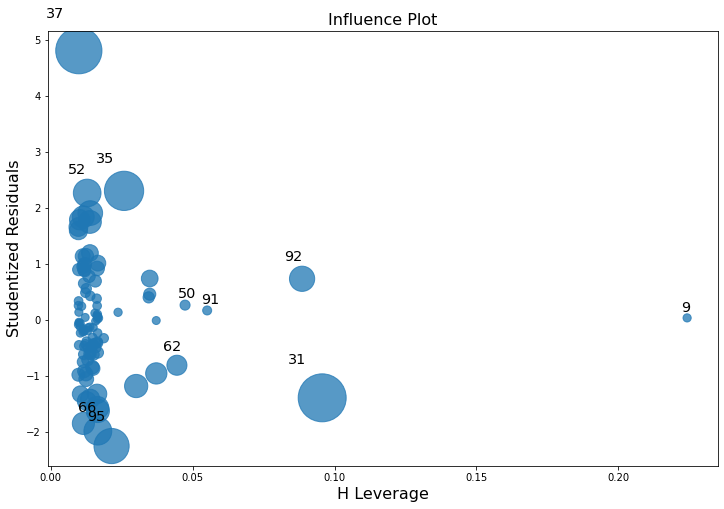

In [ ]:
#print(df1_cl)
#print(df2_cl)
#print(df1_cl-df2_cl)
exp_change= (df1_cl-df2_cl)/df1_cl
soi_exp= compute_soi_exp(country_list, product_list,country_list_18, product_list_18, opportunity_gain, exp_change)
print(sorted(soi_exp.items(), key=operator.itemgetter(0)))
#print(np.intersect1d(country_list,country_list_18))
reg_exp= compute_regress(soi_exp, gdp_raw, country_list, country_list_18)
reg_exp.summary()

# End

In [ ]:
print(np.sort(list(soi_adi.keys())))
print(np.sort(country_list))
print(np.sort(country_list2))

['Albania' 'Andorra' 'Antigua and Barbuda' 'Armenia' 'Aruba' 'Austria'
 'Azerbaijan' 'Barbados' 'Bosnia Herzegovina' 'Botswana' 'Brazil'
 'Bulgaria' 'Burkina Faso' 'Burundi' 'Canada' 'Chile' 'China'
 'China, Hong Kong Special Administrative Region' 'Colombia' 'Costa Rica'
 'Croatia' 'Cyprus' 'Czechia' 'Denmark' 'Ecuador' 'Egypt' 'El Salvador'
 'Estonia' 'Fiji' 'Finland' 'France, Monaco' 'Gambia' 'Georgia' 'Germany'
 'Ghana' 'Greece' 'Greenland' 'Guatemala' 'Guyana' 'Iceland' 'India'
 'Indonesia' 'Ireland' 'Israel' 'Italy' 'Japan' 'Jordan' 'Kazakhstan'
 'Kenya' 'Kuwait' 'Kyrgyzstan' "Lao People's Dem. Rep." 'Latvia' 'Lebanon'
 'Lithuania' 'Luxembourg' 'Madagascar' 'Malaysia' 'Malta' 'Mauritius'
 'Mexico' 'Mongolia' 'Montenegro' 'Morocco' 'Mozambique' 'Myanmar' 'NAFTA'
 'Namibia' 'Netherlands' 'New Zealand' 'Nicaragua' 'Nigeria'
 'Norway, Svalbard and Jan Mayen' 'Oman' 'Pakistan' 'Paraguay' 'Peru'
 'Philippines' 'Plurinational State of Bolivia' 'Poland' 'Portugal'
 'Qatar' 'Republic of K